# Laboratorul 4 — Exerciții
**Sisteme bazate pe cunoștințe · Pre-procesarea datelor II: filtre, eliminarea tendinței, interpolare, valori aberante, reducerea dimensionalității, puncte de schimbare**

Aplicați instrumentele din `Lab4_Exemple_Rezolvate.ipynb` pe date **noi**. În fiecare exercițiu **alegeți un parametru pe baza unor dovezi** (un spectru, o eroare de validare, un platou…) și apoi explicați alegerea.

* **Partea 1 – Filtre** (11 exerciții): semnale sintetice cu componente ascunse, apoi date de trafic și de birou inteligent.
* **Partea 2 – Eliminarea tendinței** (7 exerciții): gradul polinomului, fereastra, diferențierea, frecvența de tăiere, testul ADF, STL; trafic și EEG.
* **Partea 3 – Interpolare** (7 exerciții): recensământul golurilor, metode față de lungimea golului, depășirea, momente de timp neregulate, validare prin mascare pe trafic și birou.
* **Partea 4 – Valori aberante** (8 exerciții): scor z, MAD, IQR, Hampel, Isolation Forest, DBSCAN; birou inteligent și trafic.
* **Partea 5 – Reducerea dimensionalității** (7 exerciții): scalare, numărul de componente, reconstrucție, selecție, scurgerea de informație, t-SNE, EEG.
* **Partea 6 – Puncte de schimbare** (9 exerciții): CUSUM, penalizare, cost, `min_size`, marjă, curățare; EEG și birou.
* **Partea 7 – Pipeline** (2 exerciții + un mini-proiect deschis).

Fișiere necesare în folderul caietului: `sleepy_driver_eeg_data.csv`, `Metro_Interstate_Traffic_Volume.csv`, `smart_office_dataset.csv`.

Dificultate: ★☆☆ încălzire · ★★☆ standard · ★★★ provocare. Autoverificările afișează ✅ sau ❌ + un indiciu. Numerele sunt comparate **după rotunjirea la 2 zecimale**, iar valorile așteptate sunt stocate ca amprente, deci nu puteți citi răspunsurile – trebuie să le calculați; unele verificări sunt condiții (✅ când rezultatul vostru are proprietatea așteptată). Rulați exercițiile **în ordine**: cele următoare folosesc variabile din cele anterioare. Un traceback roșu într-o autoverificare înseamnă doar că exercițiul nu este încă rezolvat.

Fiecare exercițiu se încheie cu **Gândiți** sau **Scrieți**: răspundeți în celula markdown *„Interpretarea voastră”*; explicația **de ce** o valoare a parametrului este bună valorează la fel de mult ca numărul.

**Predare:** *Kernel → Restart & Run All*, asigurați-vă că toate verificările sunt ✅ și că **răspunsurile scrise** (celulele markdown) și graficele sunt prezente. Predați fișierul `.ipynb`.

In [2]:
%pip install ruptures

Note: you may need to restart the kernel to use updated packages.


In [4]:
import hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal, interpolate, stats

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
PINK, BLUE, GREY, GREEN, BURG = "#A33573", "#2A7F9E", "#9AA0A6", "#1C7C54", "#4D1434"
plt.rcParams.update({"figure.dpi": 100, "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12,
                     "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11,
                     "axes.titleweight": "bold", "legend.frameon": False})

def gain_db(sos, f, fs):
    """Câștigul (dB) unui filtru în secțiuni de ordinul doi la frecvența f (Hz)."""
    _, h = signal.sosfreqz(sos, worN=[f], fs=fs)
    return float(20 * np.log10(np.abs(h[0]) + 1e-12))

def prf(flag, truth):
    """Precizie, recall, F1 ale unei detecții booleene față de un adevăr boolean."""
    flag, truth = np.asarray(flag, bool), np.asarray(truth, bool)
    tp = int((flag & truth).sum()); fp_ = int((flag & ~truth).sum()); fn = int((~flag & truth).sum())
    p = tp / (tp + fp_) if tp + fp_ else 0.0; r = tp / (tp + fn) if tp + fn else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)

import ruptures as rpt
from ruptures.metrics import precision_recall
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import STL
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, KFold
from sklearn.feature_selection import SelectKBest, f_classif, VarianceThreshold
from sklearn.ensemble import IsolationForest
from sklearn.cluster import DBSCAN
from sklearn.manifold import TSNE, trustworthiness
from sklearn.impute import KNNImputer

def _norm(v):
    if isinstance(v, (bool, np.bool_)): return str(bool(v))
    if isinstance(v, (int, float, np.integer, np.floating)): return f"{float(v):.2f}"
    return str(v)

def check(label, condition, hint=""):
    """Autoverificare: bifă verde dacă condiția este îndeplinită, altfel un indiciu. Nu modificați."""
    print(("✅ " if condition else "❌ ") + label + ("" if condition else f"   → indiciu: {hint}"))

def check_value(label, value, code, hint=""):
    """Compară valoarea voastră (numerele rotunjite la 2 zecimale) cu o amprentă a valorii așteptate."""
    ok = hashlib.sha256(_norm(value).encode()).hexdigest()[:8] == code
    print(("✅ " if ok else "❌ ") + label + ("" if ok else f"   → indiciu: {hint}"))

# ---------- funcții ajutătoare și generatoare de date folosite de exerciții (nu le modificați) ----------
from scipy.ndimage import median_filter

def lag(a, b):
    "întârzierea lui a față de b, în eșantioane (pozitiv = a întârzie)"
    c = signal.correlate(np.asarray(a) - np.mean(a), np.asarray(b) - np.mean(b), mode="full")
    return int(np.argmax(c) - (len(b) - 1))

def hampel(s, window=11, n_sigmas=3, floor=0.0):
    s = pd.Series(s); med = s.rolling(window, center=True, min_periods=1).median()
    mad = 1.4826 * (s - med).abs().rolling(window, center=True, min_periods=1).median()
    return ((s - med).abs() > n_sigmas * np.maximum(mad, floor)).values

def sigma_hat(v):
    "nivelul robust de zgomot al unei serii constante pe porțiuni, din primele diferențe"
    d = np.diff(v); return np.median(np.abs(d - np.median(d))) / (np.sqrt(2) * 0.6745)

# ---- Partea 1 ----
def make_mix(seed, fs=200, seconds=10):
    "ton util (frecvență întreagă ascunsă) + derivă lentă + rețea 50 Hz + zgomot"
    rng = np.random.default_rng(seed); t = np.arange(0, seconds, 1 / fs)
    f_sig = int(rng.integers(9, 15)); f_dr = float(rng.uniform(0.2, 0.5))
    x = 3 * np.sin(2 * np.pi * f_sig * t) + 6 * np.sin(2 * np.pi * f_dr * t) + 1.5 * np.sin(2 * np.pi * 50 * t) + 0.5 * rng.normal(size=t.size)
    return t, x

def make_spiky(seed, n=1500):
    "curbă netedă + zgomot + vârfuri late de 3 eșantioane. returnează: curat, cu zgomot fără vârfuri, cu vârfuri"
    rng = np.random.default_rng(seed); k = np.arange(n)
    clean = 5 * np.sin(2 * np.pi * k / 150) + 3 * np.sin(2 * np.pi * k / 61 + 1)
    nz = clean + 0.8 * rng.normal(size=n); sp = nz.copy()
    for p0 in rng.choice(np.arange(20, n - 20, 40), 15, replace=False): sp[p0:p0 + 3] += 15
    return clean, nz, sp

# ---- Partea 2 ----
def make_trended(seed, n=14 * 24):
    "serie orară: tendință polinomială ascunsă + ciclu de 24 h + zgomot. returnează y, true_trend"
    rng = np.random.default_rng(seed); h = np.arange(n)
    trend = 30 + 0.04 * h + rng.uniform(1e-4, 2e-4) * h**2
    return trend + 7 * np.sin(2 * np.pi * h / 24 + 0.5) + 2 * rng.normal(size=n), trend

def make_walks(seed, m=600):
    "tendință + zgomot și mers aleator cu derivă"
    rng = np.random.default_rng(seed); tt = np.arange(m)
    return 0.05 * tt + rng.normal(size=m), np.cumsum(0.05 + rng.normal(size=m))

# ---- Partea 3 ----
def make_wave(seed, N=600):
    "două sinusoide (perioade ascunse)"
    rng = np.random.default_rng(seed); k = np.arange(N)
    return 10 * np.sin(2 * np.pi * k / 50) + 3 * np.sin(2 * np.pi * k / 13 + 1) + 0.05 * rng.normal(size=N)

# ---- Partea 4 ----
def make_values(seed, n=1000, frac=0.01, shift=8):
    rng = np.random.default_rng(seed); v = rng.normal(50, 5, n); truth = np.zeros(n, bool)
    idx = rng.choice(n, int(frac * n), replace=False); v[idx] += rng.choice([-1, 1], len(idx)) * rng.uniform(shift, shift + 4, len(idx)) * 5; truth[idx] = True
    return v, truth

def make_level_series(seed, n=1500):
    rng = np.random.default_rng(seed); tt = np.arange(n)
    ts = 50 + 25 * np.sin(2 * np.pi * tt / 500) + rng.normal(0, 1.5, n); truth = np.zeros(n, bool)
    pos = rng.choice(np.arange(10, n - 10), 25, replace=False); ts[pos] += rng.choice([-1, 1], 25) * rng.uniform(8, 15, 25); truth[pos] = True
    return ts, truth

def make_blobs2d(seed, unit2=1.0):
    rng = np.random.default_rng(seed)
    A = rng.normal([0, 0], [1, 1], (300, 2)); B = rng.normal([6, 5], [0.7, 1.2], (300, 2)); O = rng.uniform(-4, 10, (12, 2))
    X = np.vstack([A, B, O]); X[:, 1] *= unit2
    return X, np.r_[np.zeros(600, bool), np.ones(12, bool)]

# ---- Partea 5 ----
def make_latent(seed=0, n=600):
    rng = np.random.default_rng(seed)
    F = rng.normal(size=(n, 3)) * np.array([3.0, 2.0, 1.5]); M = rng.normal(size=(3, 10))
    X = F @ M + 0.6 * rng.normal(size=(n, 10))
    scale = np.array([1, 1, 1, 10, 10, 100, 100, 1000, 1, 1.0])
    y = (F[:, 0] + 0.3 * rng.normal(size=n) > 0).astype(int)
    return pd.DataFrame(X * scale, columns=[f"f{i}" for i in range(10)]), y

def make_noise_task(seed, n=100, p=500):
    "etichetele sunt aleatoare: nicio trăsătură nu poartă informație"
    rng = np.random.default_rng(seed); return rng.normal(size=(n, p)), rng.integers(0, 2, n)

# ---- Partea 6 ----
def make_one_shift(seed, n=600, delta=2.0):
    rng = np.random.default_rng(seed); t0 = int(rng.integers(220, 380))
    return np.r_[rng.normal(0, 1, t0), rng.normal(delta, 1, n - t0)], t0

def make_mean_series(seed):
    rng = np.random.default_rng(seed); a, b = int(rng.integers(120, 180)), int(rng.integers(320, 380))
    x = np.r_[rng.normal(0, 1, a), rng.normal(3, 1, b - a), rng.normal(1, 1, 500 - b)]
    return x, [a, b]

def make_var_series(seed):
    rng = np.random.default_rng(seed); a = int(rng.integers(250, 350))
    return np.r_[rng.normal(0, 1, a), rng.normal(0, 4, 600 - a)], [a]

def make_burst_series(seed):
    rng = np.random.default_rng(seed); a = int(rng.integers(200, 300))
    return np.r_[rng.normal(0, 1, a), rng.normal(5, 1, 6), rng.normal(0, 1, 600 - a - 6)], [a, a + 6]

def cusum_alarms(x, mu0, sigma, k=0.5, h=5.0):
    "CUSUM bilateral; k și h în unități de sigma. Returnează indexul primei alarme (sau None)."
    gp = gm = 0.0
    for i, v in enumerate(x):
        z = (v - mu0) / sigma; gp = max(0.0, gp + z - k); gm = max(0.0, gm - z - k)
        if gp > h or gm > h: return i
    return None

# Partea 1 — Proiectarea filtrelor

Frecvența de eșantionare a exercițiilor sintetice: `fs = 200 Hz`. `make_mix(seed)` dă un semnal cu un ton **ascuns**, o derivă lentă ascunsă, rețeaua de 50 Hz și zgomot.

## 1.1 · Citiți spectrul  ★☆☆

`t, x = make_mix(11)`. Calculați spectrul Welch cu `signal.welch(x, fs=fs, nperseg=1000)` și găsiți vârfurile cu `signal.find_peaks(Pxx, height=20 * np.median(Pxx))`.

* `n_peaks` – numărul de vârfuri găsite;
* `f_signal` – frecvența (Hz, **rotunjită la un număr întreg**) a celui mai mare vârf între 5 și 40 Hz;
* `f_main` – frecvența (rotunjită) a vârfului de peste 45 Hz.

**Gândiți:** a treia componentă (deriva lentă) nu se află printre vârfuri. De ce nu? Ce parametru Welch ați schimba ca s-o vedeți?

In [5]:
fs = 200
t, x = make_mix(11)
f, Pxx = signal.welch(x, fs=fs, nperseg=1000)
peaks, props = signal.find_peaks(Pxx, height=20*np.median(Pxx))
f_peaks = f[peaks]

n_peaks = len(peaks)
cmp = max([t for t in f_peaks if t > 5 and t < 40])
f_signal = int(cmp)
f_main = round(max(peaks))

In [6]:
print(peaks)
print(props)
print(f_peaks)

[  2  45 250]
{'peak_heights': array([55.32030065, 14.76712838,  3.77352677])}
[ 0.4  9.  50. ]


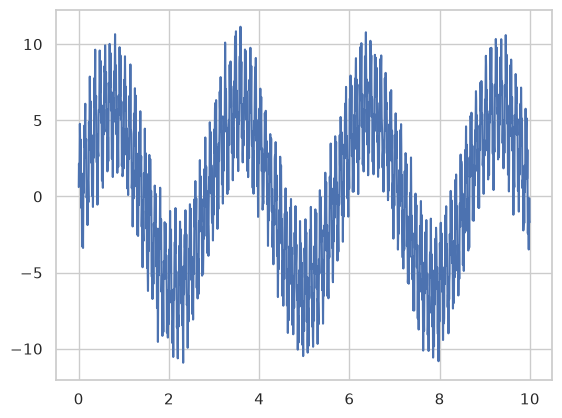

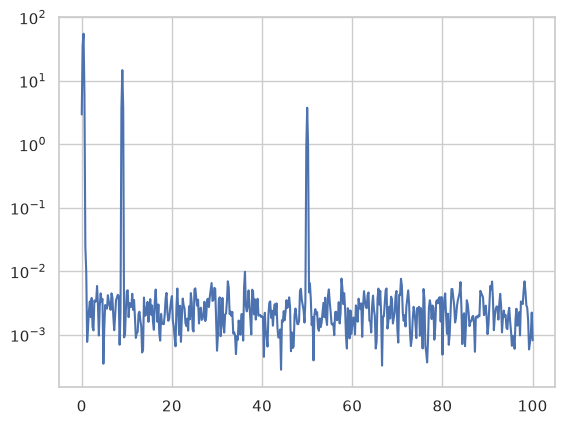

In [7]:
plt.plot(t, x)
plt.show()
plt.semilogy(f, Pxx)
plt.show()

**Autoverificare**

In [8]:
fs, n_peaks, f_signal, f_main

(200, 3, 9, 250)

In [9]:
check_value("n_peaks", n_peaks, "a97491cd", "Welch + find_peaks(height=...)")
check_value("f_signal", f_signal, "4cc019de", "frecven\u021ba celui mai mare v\u00e2rf \u00eentre 5 \u0219i 40 Hz, rotunjit\u0103 la \u00eentreg")
check_value("f_main", f_main, "a9921087", "v\u00e2rful din apropiere de 50 Hz, rotunjit")

✅ n_peaks
✅ f_signal
❌ f_main   → indiciu: vârful din apropiere de 50 Hz, rotunjit


**Interpretarea voastră:** _scrieți aici_

## 1.2 · Cele patru tipuri clasice: alegeți tipul, apoi ordinul  ★★☆

Același semnal ca la 1.1 (`t, x = make_mix(11)`, `fs = 200`). Cele trei componente ale sale sunt deriva lentă la `f_drift = 0.35` Hz, tonul dorit la `f_signal` Hz (de la 1.1) și rețeaua la 50 Hz.

**a)** Proiectați patru filtre Butterworth de ordin 4 cu `output="sos"`: un **trece-jos** (`fc = 30`), un **trece-sus** (`fc = 2`), un **trece-bandă** (`[5, 30]`) și un **oprește-bandă** (`[45, 55]`). Pentru fiecare numărați câte dintre cele trei componente le **păstrează**, adică câștigul la frecvența componentei este peste **−3 dB** (folosiți `gain_db(sos, f, fs)`):

* `kept_lp`, `kept_hp`, `kept_bp`, `kept_bs`.

**b)** Folosiți `signal.buttord(wp, ws, gpass=1, gstop=30, fs=fs)` și păstrați doar ordinul `N` (prima valoare returnată):

* `N_hp` – trece-sus: banda de trecere de la 8 Hz, banda de oprire sub 2 Hz;
* `N_bp` – trece-bandă: banda de trecere `[8, 14]`, benzile de oprire sub 4 Hz și peste 20 Hz;
* `N_bs` – oprește-bandă: marginile benzii de trecere `[40, 60]`, banda de oprire `[48, 52]`;
* `N_bp_narrow` – trece-banda lui `N_bp` cu marginile benzii de oprire mutate mai aproape, `ws = [7, 15]`.

**Scrieți:** pentru fiecare dintre cele patru probleme *eliminați doar rețeaua de 50 Hz · eliminați deriva lentă · păstrați ritmul alfa 8–12 Hz și nimic altceva · eliminați zgomotul peste 40 Hz* numiți tipul de filtru și frecvența (frecvențele) de tăiere pe care le-ați folosi. Apoi explicați de ce `N_bp_narrow` este mult mai mare decât `N_bp`: ce costă lățimea **benzii de tranziție**?

In [10]:
from scipy.signal import butter, sosfiltfilt

# a)
f_drift = 0.35
comps = [f_drift, f_signal, 50]
order = 4
sos_lp = butter(N=order, Wn=30, btype='lowpass', fs=fs, output='sos')
sos_hp = butter(N=order, Wn=2, btype='highpass', fs=fs, output='sos')
sos_bp = butter(N=order, Wn=[5, 30], btype='bandpass', fs=fs, output='sos')
sos_bs = butter(N=order, Wn=[45, 55], btype='bandstop', fs=fs, output='sos')

kept_lp = sum(gain_db(sos_lp, f, fs) > -3 for f in comps)
kept_hp = sum(gain_db(sos_hp, f, fs) > -3 for f in comps)
kept_bp = sum(gain_db(sos_bp, f, fs) > -3 for f in comps)
kept_bs = sum(gain_db(sos_bs, f, fs) > -3 for f in comps)

In [11]:
kept_lp, kept_hp, kept_bp, kept_bs

(2, 2, 1, 2)

In [12]:
# b)
N_hp = signal.buttord(wp=8, ws=2, gpass=1, gstop=30, fs=fs)[0]
N_bp = signal.buttord(wp=[8, 14], ws=[4, 20], gpass=1, gstop=30, fs=fs)[0]
N_bs = signal.buttord(wp=[40, 60], ws=[48, 52], gpass=1, gstop=30, fs=fs)[0]
N_bp_narrow = signal.buttord(wp=[8, 14], ws=[7, 15], gpass=1, gstop=30, fs=fs)[0]

In [13]:
N_hp, N_bp, N_bs, N_bp_narrow

(3, 5, 3, 18)

**Autoverificare**

In [14]:
check_value("kept_lp", kept_lp, "9f770654", "num\u0103ra\u021bi componentele al c\u0103ror c\u00e2\u0219tig este peste -3 dB")
check_value("kept_hp", kept_hp, "9f770654", "trece-susul de 2 Hz elimin\u0103 doar deriva")
check_value("kept_bp", kept_bp, "cf9dcf6d", "trece-banda p\u0103streaz\u0103 doar ce este \u00een interiorul benzii")
check_value("kept_bs", kept_bs, "9f770654", "opre\u0219te-banda elimin\u0103 doar re\u021beaua")
check_value("N_hp", N_hp, "a97491cd", "buttord(wp=8, ws=2, ...): la un trece-sus banda de oprire este SUB banda de trecere")
check_value("N_bp", N_bp, "9ae1524b", "buttord(wp=[8, 14], ws=[4, 20], ...)")
check_value("N_bs", N_bs, "a97491cd", "buttord(wp=[40, 60], ws=[48, 52], ...): la un opre\u0219te-band\u0103 banda de oprire este \u00ceN INTERIORUL marginilor benzii de trecere")
check_value("N_bp_narrow", N_bp_narrow, "3dbbd4fa", "buttord(wp=[8, 14], ws=[7, 15], ...)")
check("o bandă de tranziție mai îngustă cere un ordin mai mare", N_bp_narrow > N_bp, "același trece-bandă, cu marginile benzii de oprire mai aproape de banda de trecere")

✅ kept_lp
✅ kept_hp
✅ kept_bp
✅ kept_bs
✅ N_hp
✅ N_bp
✅ N_bs
✅ N_bp_narrow
✅ o bandă de tranziție mai îngustă cere un ordin mai mare


**Interpretarea voastră:** _scrieți aici_

## 1.3 · Media mobilă proiectată pentru o frecvență  ★★☆

* `w_mains` – lungimea ferestrei (eșantioane) al cărei **prim zero este la 50 Hz** (`fs / 50`);
* `gain_signal_db` – câștigul (dB) acelei medii mobile la `f_signal` (`signal.freqz(np.ones(w)/w, 1, worN=[f_signal], fs=fs)`; câștig = `20*log10(abs(H))`);
* `gain_main_db_w5` – câștigul (dB) la 50 Hz al unei ferestre de **5** eșantioane (rotunjiți valoarea la 2 zecimale).

**Gândiți:** o fereastră de 5 este „aproape” 4. De ce este atenuarea la 50 Hz mult mai slabă?

In [15]:
w_mains = int(fs / 50)

_, H = signal.freqz(np.ones(w_mains) / w_mains, 1, worN=[f_signal], fs=fs)
gain_signal_db = 20 * np.log10(np.abs(H[0]))

w5 = 5
_, H5 = signal.freqz(np.ones(w5) / w5, 1, worN=[50], fs=fs)
gain_main_db_w5 = round(float(20 * np.log10(np.abs(H5[0]))), 2)

In [16]:
w_mains, gain_signal_db, gain_main_db_w5

(4, np.float64(-0.43900708238137603), -13.98)

**Autoverificare**

In [17]:
check_value("w_mains", w_mains, "8c9d9d6d", "fs / 50")
check_value("gain_signal_db", gain_signal_db, "09d5ad83", "20*log10(|H|) la f_signal")
check_value("gain_main_db_w5", gain_main_db_w5, "c9baeb23", "w = 5 NU are zeroul la 50 Hz")

✅ w_mains
✅ gain_signal_db
✅ gain_main_db_w5


**Interpretarea voastră:** _scrieți aici_

## 1.4 · Butterworth dintr-o specificație  ★★☆

Specificație (fs = 200 Hz): bandă de trecere până la **20 Hz** cu cel mult **1 dB** pierdere, bandă de oprire de la **45 Hz** cu cel puțin **40 dB** atenuare.

* `N, Wn = signal.buttord(...)` – cel mai mic ordin și frecvența de tăiere; păstrați `N`;
* `sos` – trece-josul `signal.butter(N, Wn, 'low', fs=fs, output='sos')`;
* `gain50_db` – câștigul lui la frecvența rețelei (`gain_db(sos, 50, fs)` este furnizată).

**Gândiți:** cu aceeași specificație, dar cu banda de oprire începând de la 30 Hz, ce s-ar întâmpla cu ordinul? Încercați.

In [18]:
N, Wn = signal.buttord(wp=20, ws=45, gpass=1, gstop=40, fs=fs)
sos = signal.butter(N, Wn, 'low', fs=fs, output='sos')
gain50_db = gain_db(sos, 50, fs)

In [19]:
N, Wn, len(sos), gain50_db

(6, np.float64(22.20396216187887), 3, -52.71864535065923)

**Autoverificare**

In [20]:
check_value("N", N, "017144e2", "buttord(wp=20, ws=45, gpass=1, gstop=40, fs=fs)")
check_value("gain50_db", gain50_db, "4a8e087d", "gain_db(sos, 50, fs)")
check("filtrul îndeplinește specificația de 40 dB la 45 Hz", gain_db(sos, 45, fs) <= -40, "ordinul este cel mai mic care îndeplinește specificația: verificați gain_db(sos, 45, fs)")

✅ N
✅ gain50_db
✅ filtrul îndeplinește specificația de 40 dB la 45 Hz


**Interpretarea voastră:** _scrieți aici_

## 1.5 · Prețul cauzalității  ★★☆

`ref` este o sinusoidă curată de 8 Hz eșantionată la 200 Hz (2 s). Filtrați-o cu un **trece-jos Butterworth de ordin 4, frecvență de tăiere 20 Hz** (`sos`, `fs=fs`):

* `y_causal = signal.sosfilt(...)`, `y_zero = signal.sosfiltfilt(...)`;
* `lag_causal`, `lag_zero` – întârzierea lor față de `ref`, în eșantioane (`lag(a, b)` este furnizată);
* `delay_ms` – întârzierea cauzală în milisecunde.

**Gândiți:** întârzierea unui filtru cauzal depinde de frecvență. Ce înseamnă asta pentru o formă de undă alcătuită din mai multe frecvențe, cum este o bătaie ECG?

In [21]:
tt = np.arange(0, 2, 1 / fs)
ref = np.sin(2 * np.pi * 8 * tt)

sos = signal.butter(4, 20, 'low', fs=fs, output='sos')
y_causal = signal.sosfilt(sos=sos, x=ref)
y_zero = signal.sosfiltfilt(sos=sos, x=ref)

lag_causal = lag(y_causal, ref)
lag_zero = lag(ref, y_zero)
delay_ms = lag_causal / fs * 1000

In [22]:
lag_causal, lag_zero, delay_ms

(4, 0, 20.0)

**Autoverificare**

In [23]:
check_value("lag_causal", lag_causal, "8c9d9d6d", "lag(y_causal, ref)")
check_value("lag_zero", lag_zero, "561b2814", "sosfiltfilt nu introduce \u00eent\u00e2rziere")
check_value("delay_ms", delay_ms, "b9e68997", "lag_causal / fs * 1000")

✅ lag_causal
✅ lag_zero
✅ delay_ms


**Interpretarea voastră:** _scrieți aici_

## 1.6 · FIR sau IIR pentru aceeași specificație?  ★★★

Aceeași specificație ca la 1.4 (bandă de trecere 20 Hz, bandă de oprire 45 Hz, 40 dB; `fs = 200`).

* `numtaps, beta = signal.kaiserord(ripple=40, width=25 / (fs / 2))`; dacă `numtaps` este par, adăugați 1 (lungime impară → întârziere întreagă);
* `fir_delay_ms` – întârzierea constantă a acelui filtru FIR în milisecunde, `(numtaps − 1) / 2 / fs · 1000`;
* `n_coef_iir` – numărul de coeficienți ai filtrului IIR de la 1.4 (`sos.size`).

**Gândiți:** FIR-ul are de circa 3 ori mai mulți coeficienți, dar întârzierea lui este exact aceeași pentru orice frecvență. Când merită acest cost?

In [24]:
numtaps, beta = signal.kaiserord(ripple=40, width=25 / (fs / 2))
fir_delay_ms = (numtaps - 1) / 2 / fs * 1000

sos_iir = signal.iirdesign(wp=20, ws=45, gpass=1, gstop=40, ftype='butter' , fs=fs, output='sos')
n_coef_iir = sos_iir.size

In [25]:
numtaps, fir_delay_ms, n_coef_iir

(19, 45.0, 18)

**Autoverificare**

In [26]:
check_value("numtaps", numtaps, "df644619", "kaiserord(ripple=40, width=25/(fs/2)); face\u021bi-l impar")
check_value("fir_delay_ms", fir_delay_ms, "bc7a1ad0", "(numtaps-1)/2/fs*1000")
check_value("n_coef_iir", n_coef_iir, "3dbbd4fa", "sos.size pentru ordinul g\u0103sit la 1.4")

✅ numtaps
✅ fir_delay_ms
✅ n_coef_iir


**Interpretarea voastră:** FIR este util daca forma de unda / faza trebuie pastrata ori de cate ori stabilitatea este prioritara

## 1.7 · Un notch cu factorul de calitate potrivit  ★★☆

Eliminați rețeaua (50 Hz), dar deteriorați cât mai puțin frecvențele vecine.

* `Q_needed` – factorul de calitate pentru un notch a cărui **lățime de bandă la −3 dB este 2 Hz** (`Q = f0 / lățime de bandă`);
* `gain48_q5_db`, `gain48_q25_db` – câștigul (dB, cu `signal.freqz(b, a, worN=[...], fs=fs)`) la **48 Hz** pentru `Q = 5` și pentru `Q_needed`;
* `gain_sig_q5_db` – câștigul (dB) notch-ului cu `Q = 5` la `f_signal`.

**Gândiți:** cu `Q = 5`, cât din tonul dorit se pierde? Ce plătiți pentru un Q foarte mare (de exemplu 200)?

In [27]:
f0 = 50.0
BW = 2.0

Q_needed = f0 / BW
b1, a1 = signal.iirnotch(f0, Q=5, fs=fs)
_, H1 = signal.freqz(b1, a1, worN=[48], fs=fs)
gain48_q5_db = float(20 * np.log10(np.abs(H1[0])))

b2, a2 = signal.iirnotch(f0, Q=Q_needed, fs=fs)
_, H2 = signal.freqz(b2, a2, worN=[48], fs=fs)
gain48_q25_db = float(20 * np.log10(np.abs(H2[0])))

_, H3 = signal.freqz(b1, a1, worN=[f_signal], fs=fs)
gain_sig_q5_db = float(20 * np.log10(np.abs(H3[0])))

In [28]:
Q_needed, gain48_q5_db, gain48_q25_db, gain_sig_q5_db

(25.0, -8.655509197631023, -0.9673849840093657, -0.00918591735683617)

**Autoverificare**

In [29]:
check_value("Q_needed", Q_needed, "89b235c0", "f0 / bandwidth")
check_value("gain48_q5_db", gain48_q5_db, "cf7fd0ac", "iirnotch(50, 5, fs), apoi freqz la 48 Hz")
check_value("gain48_q25_db", gain48_q25_db, "6c975619", "iirnotch(50, Q_needed, fs), apoi freqz la 48 Hz")
check_value("gain_sig_q5_db", gain_sig_q5_db, "39ccca44", "freqz la f_signal cu Q = 5")

✅ Q_needed
✅ gain48_q5_db
✅ gain48_q25_db
✅ gain_sig_q5_db


**Interpretarea voastră:** _scrieți aici_

## 1.8 · Vârfuri: dimensiunea nucleului median  ★★☆

`clean, noisy, spiky = make_spiky(5)`: `spiky` conține 15 vârfuri **late de 3 eșantioane**. Pentru `kernel` în `[3, 5, 7, 9, 11, 15, 21]`:

* `best_kernel` – nucleul cu cel mai mic RMSE al lui `signal.medfilt(spiky, kernel)` față de `clean`; `rmse_best_median` – RMSE-ul lui;
* același lucru pentru ferestrele mediei mobile `[3, 5, 7, 9, 11, 15, 21]` (`np.convolve(spiky, np.ones(w)/w, 'same')`): `best_ma` și `rmse_best_ma`.

**Gândiți:** cel mai bun nucleu este mai mare decât dublul lățimii vârfului. De ce? Și de ce crește RMSE din nou pentru nuclee mari?

In [30]:
clean, noisy, spiky = make_spiky(5)
ks = [3, 5, 7, 9, 11, 15, 21]

med_rmses = { k: float(np.sqrt(np.mean((signal.medfilt(spiky, k) - clean) ** 2))) for k in ks }
best_kernel = min(med_rmses, key=med_rmses.get)

rmse_best_median = med_rmses[best_kernel]

ma_rmses = { w: float(np.sqrt(np.mean( (np.convolve(spiky, np.ones(w) / w, mode='same') - clean) ** 2 ))) for w in ks }
best_ma = min(ma_rmses, key=ma_rmses.get)
rmse_best_ma = ma_rmses[best_ma]

In [31]:
best_kernel, rmse_best_median, best_ma, rmse_best_ma

(9, 0.4285266220620615, 21, 1.082496372992209)

**Autoverificare**

In [32]:
check_value("best_kernel", best_kernel, "4cc019de", "argmin al RMSE peste nuclee")
check_value("rmse_best_median", rmse_best_median, "6d49251b", "RMSE vs clean")
check_value("best_ma", best_ma, "111ffe69", "fereastra celei mai bune medii mobile")
check("filtrul median bate cea mai bună medie mobilă", rmse_best_median < rmse_best_ma, "comparați cele două RMSE")

✅ best_kernel
✅ rmse_best_median
✅ best_ma
✅ filtrul median bate cea mai bună medie mobilă


**Interpretarea voastră:** _scrieți aici_

## 1.9 · Savitzky–Golay: fereastra și ordinul polinomului  ★★☆

Pe curba cu zgomot **fără vârfuri** (`noisy` de la 1.8) căutați perechea `(window_length, polyorder)` cu cel mai mic RMSE față de `clean`: ferestre `[5, 9, 15, 21, 31, 51, 81, 121]`, `polyorder` în `[1, 2, 3, 4]` (săriți perechile cu `polyorder >= window_length`). La RMSE egal păstrați prima pereche găsită.

* `best_sg_window`, `best_sg_poly`, `rmse_sg_best`.

**Gândiți:** curba curată are oscilații lente (perioade de 150 și 61 de eșantioane). Este cea mai bună fereastră legată de cea mai scurtă dintre aceste perioade?

In [33]:
kernel = [5, 9, 15, 21, 31, 51, 81, 121]
polyorder = [1, 2, 3, 4]

best_sg_window = None
best_sg_poly = None
rmse_sg_best = np.inf

for w in kernel:
    for p in polyorder:
        if p >= w:
            continue
        filtered = signal.savgol_filter(noisy, window_length=w, polyorder=p)
        rmse = float(np.sqrt(np.mean((filtered - clean) ** 2)))

        if rmse < rmse_sg_best:
            rmse_sg_best = rmse
            best_sg_window = w
            best_sg_poly = p

In [34]:
best_sg_window, best_sg_poly, rmse_sg_best

(51, 4, 0.21628033640881228)

**Autoverificare**

In [35]:
check_value("best_sg_window", best_sg_window, "2e3bb484", "argmin peste (fereastr\u0103, polyorder)")
check_value("best_sg_poly", best_sg_poly, "8c9d9d6d", "argmin peste (fereastr\u0103, polyorder)")
check_value("rmse_sg_best", rmse_sg_best, "dc08a4e8", "RMSE vs clean")

✅ best_sg_window
✅ best_sg_poly
✅ rmse_sg_best


**Interpretarea voastră:** _scrieți aici_

## 1.10 · Date reale (trafic): împărțiți seria pe frecvențe  ★★☆

Traficul orar din **ianuarie–septembrie 2018** (fișierul se termină la 30 septembrie) (`fs = 1` eșantion/oră). Construiți `vol` ca în exemplul rezolvat: reindexați `2018-01-01 … 2018-09-30 23:00` pe o grilă orară completă și `interpolate(method="time")`.

* `sos_week`: **trece-bandă** Butterworth, **ordin 2, `[1/200, 1/100]` cicluri/oră** (perioade între 100 și 200 de ore: partea cu variație lentă); `std_slow` = abaterea standard a lui `signal.sosfiltfilt(sos_week, vol.values)`;
* `sos_day`: **trece-bandă, ordin 2, `[1/30, 1/20]`**; `std_daily` = abaterea standard a ieșirii sale.

**Gândiți:** care dintre cele două benzi poartă cea mai multă varianță? Ce se află în rest, adică ce frecvențe nu sunt în niciuna dintre benzi?

In [36]:
tr = pd.read_csv("Metro_Interstate_Traffic_Volume.csv", parse_dates=["date_time"]).drop_duplicates("date_time").set_index("date_time")

In [37]:
tr.head(n=10)

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,traffic_volume
date_time,,,,,,,,
2012-10-02 09:00:00,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,5545
2012-10-02 10:00:00,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,4516
2012-10-02 11:00:00,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,4767
2012-10-02 12:00:00,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,5026
2012-10-02 13:00:00,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,4918
2012-10-02 14:00:00,NaN,291.72,0.0,0.0,1,Clear,sky is clear,5181
2012-10-02 15:00:00,NaN,293.17,0.0,0.0,1,Clear,sky is clear,5584
2012-10-02 16:00:00,NaN,293.86,0.0,0.0,1,Clear,sky is clear,6015
2012-10-02 17:00:00,NaN,294.14,0.0,0.0,20,Clouds,few clouds,5791


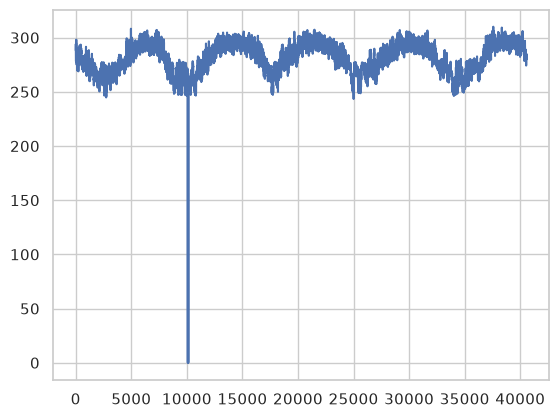

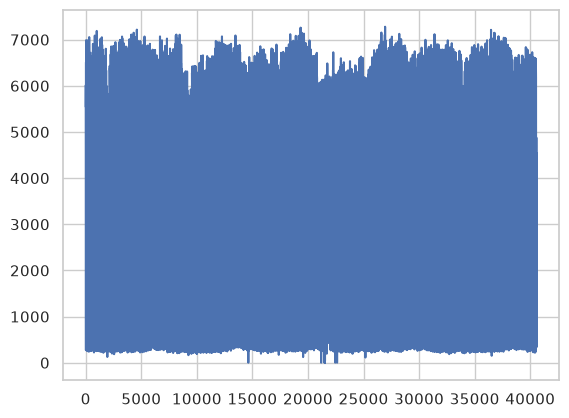

In [38]:
t = range(len(tr))
plt.plot(t, tr['temp'])
plt.show()
plt.plot(t, tr['traffic_volume'])

In [39]:
id_date = pd.date_range("2018-01-01 00:00:00", "2018-09-30 23:00:00", freq="h")
vol = tr.loc["2018-01-01":"2018-09-30", "traffic_volume"].reindex(id_date).interpolate(method="time")
fs = 1.0

sos_week = signal.butter(N=2, Wn=[1 / 200, 1 / 100], btype="bandpass", fs=fs, output="sos")
y_slow = signal.sosfiltfilt(sos_week, vol.values)
std_slow = float(np.std(y_slow))


sos_day = signal.butter(N=2, Wn=[1 / 30, 1 / 20], btype="bandpass", fs=fs, output="sos")
y_day = signal.sosfiltfilt(sos_day, vol.values)
std_daily = float(np.std(y_day))

In [40]:
len(vol), std_slow, std_daily

(6552, 370.44463463257006, 1632.3911708288417)

**Autoverificare**

In [41]:
check_value("std_daily", std_daily, "9b413211", "sosfiltfilt al trece-benzii [1/30, 1/20], ordin 2")
check_value("std_slow", std_slow, "2deba627", "sosfiltfilt al trece-josului 1/48, ordin 4")
check("cele două părți împreună au mai puțină varianță decât seria brută", std_daily**2 + std_slow**2 < vol.std()**2 * 1.01, "nu ar trebui să însumeze mai mult decât varianța brută")

✅ std_daily
✅ std_slow
✅ cele două părți împreună au mai puțină varianță decât seria brută


**Interpretarea voastră:** _scrieți aici_

## 1.11 · Date reale (birou inteligent): ce netezitor pentru vârfurile de CO₂?  ★★☆

`co2 = smart_office["co2_ppm"].interpolate()` (`smart_office_dataset.csv`, indexul `timestamp`). CO₂ dintr-un birou închis nu depășește niciodată 800 ppm în aceste date, cu excepția defecțiunilor de senzor (valorile eronate sunt 150, 2100, 2250, 2400 ppm).

* `k_min` – **cel mai mic nucleu median impar** (încercați 3, 5, 7, 9) pentru care `signal.medfilt(co2.values, k).max() < 800`;
* `max_mean5` – maximul mediei mobile centrate de 5 minute (`rolling(5, center=True).mean()`), rotunjit la 2 zecimale de verificare.

**Gândiți:** vârfurile au un eșantion. Concordă regula „nucleu > 2 × lățimea vârfului” cu `k_min`? Ce ar trebui să facă media mobilă ca să îndeplinească aceeași sarcină?

In [42]:
smart_office = pd.read_csv("smart_office_dataset.csv", parse_dates=["timestamp"], index_col="timestamp")

In [43]:
smart_office.head(n=10)

,temp_c,humidity_pct,co2_ppm,occupancy,temp_out_c
timestamp,,,,,
2026-03-02 00:00:00,19.14,47.8,434.0,0,7.43
2026-03-02 00:01:00,19.02,47.8,437.0,0,7.44
2026-03-02 00:02:00,18.88,47.5,443.0,0,7.43
2026-03-02 00:03:00,18.80,48.6,445.0,0,7.38
2026-03-02 00:04:00,18.93,48.2,434.0,0,7.34
2026-03-02 00:05:00,18.98,48.2,427.0,0,7.30
2026-03-02 00:06:00,18.86,47.2,430.0,0,7.29
2026-03-02 00:07:00,18.88,48.9,439.0,0,7.28
2026-03-02 00:08:00,18.96,47.9,424.0,0,7.25


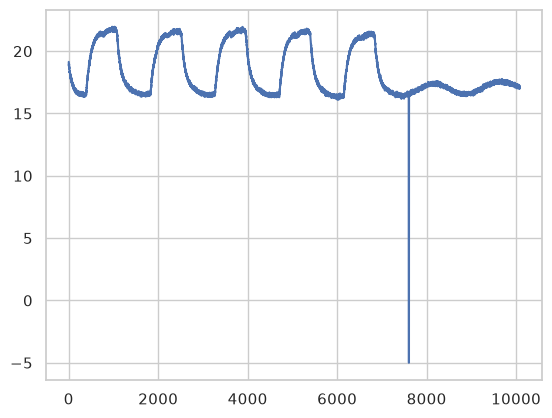

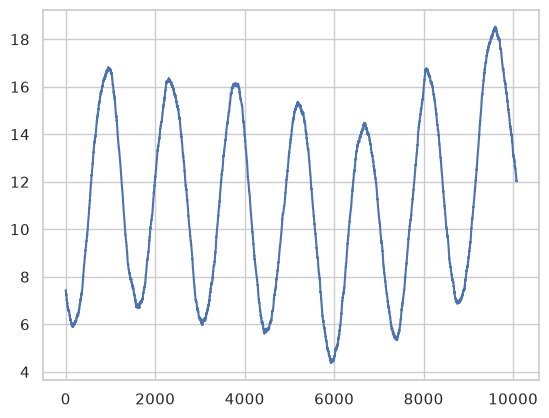

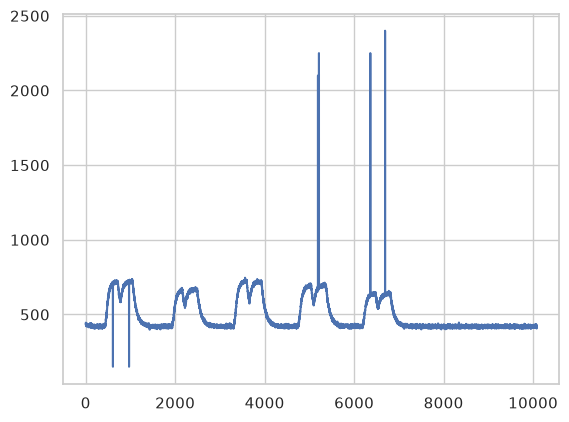

In [44]:
t = range(len(smart_office))
plt.plot(t, smart_office['temp_c'])
plt.show()
plt.plot(t, smart_office['temp_out_c'])
plt.show()
plt.plot(t, smart_office['co2_ppm'])

In [45]:
co2 = smart_office['co2_ppm'].interpolate()
krnl = [3, 5, 7, 9]
k_min = next(k for k in krnl if signal.medfilt(co2.values, k).max() < 800 )
max_mean5 = round(float(co2.rolling(5, center=True).mean().max()), 2)

In [46]:
len(co2), k_min, max_mean5

(10080, 3, 1000.0)

**Autoverificare**

In [47]:
check_value("k_min", k_min, "a97491cd", "cel mai mic nucleu impar al c\u0103rui rezultat are maximul < 800")
check_value("max_mean5", max_mean5, "78a5d5c8", "rolling(5, center=True).mean().max()")

✅ k_min
✅ max_mean5


**Interpretarea voastră:** _scrieți aici_

# Partea 2 — Proiectarea pasului de eliminare a tendinței

`make_trended(seed)` returnează o serie orară `y` (14 zile) cu o **tendință polinomială ascunsă**, un ciclu de 24 de ore și zgomot; a doua ieșire, `true_trend`, există doar pentru a *evalua* alegerile voastre.

## 2.1 · Gradul tendinței polinomiale  ★★☆

`y, true_trend = make_trended(21)`; `h = np.arange(len(y))`. Ajustați pe **primele 80 %** (`np.polynomial.Polynomial.fit(h[:split], y[:split], deg)`), măsurați RMSE pe **ultimele 20 %** pentru gradele 0…8.

* `best_degree` – cel mai **simplu** grad al cărui RMSE pe datele rezervate este în limita a 5 % față de minim (`<= 1.05 * min`) – regula parsimoniei: dintre modelele la fel de bune alegeți-l pe cel mai simplu; `rmse_test_best` – RMSE-ul pe datele rezervate al acelui grad;
* `rmse_train_1`, `rmse_train_8`, `rmse_test_8` – RMSE de antrenare pentru gradele 1 și 8, RMSE de test pentru gradul 8.

**Gândiți:** de ce trebuie ca partea de validare să fie *sfârșitul* seriei și nu 20 % din puncte alese la întâmplare? De ce arată gradele 2, 3 și 5 la fel de bune și de ce îl preferăm totuși pe cel mai mic?

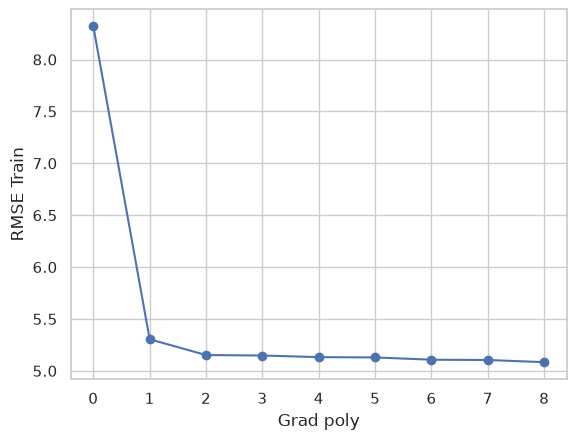

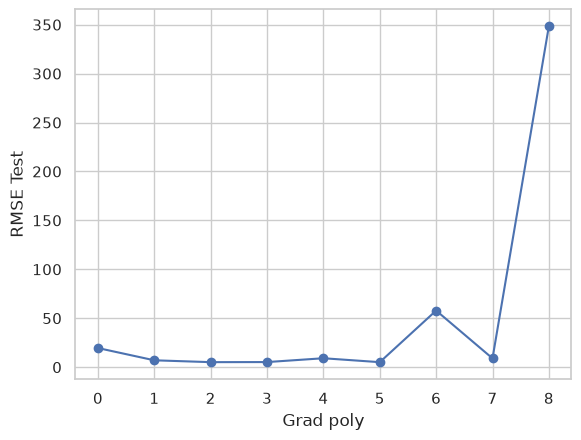

In [48]:
y, true_trend = make_trended(21)
h = np.arange(len(y)); 

ratio = int(0.8 * len(y))
degrees = (range(9))

rmse_train = {}
rmse_test = {}

for deg in degrees:
    p = np.polynomial.Polynomial.fit(h[:ratio], y[:ratio], deg)
    pred_train = p(h[:ratio])
    pred_test = p(h[ratio:])

    rmse_train[deg] = float(np.sqrt(np.mean((pred_train - y[:ratio]) ** 2)))
    rmse_test[deg] = float(np.sqrt(np.mean((pred_test - y[ratio:]) ** 2)))

plt.plot(degrees, rmse_train.values())
plt.scatter(degrees, rmse_train.values())
plt.xlabel('Grad poly')
plt.ylabel('RMSE Train')
plt.show()

plt.plot(degrees, rmse_test.values())
plt.scatter(degrees, rmse_test.values())
plt.xlabel('Grad poly')
plt.ylabel('RMSE Test')
plt.show()

In [49]:
min_rmse_test = min(rmse_test.values())
best_degree = next(deg for deg in degrees if rmse_test[deg] <= 1.05 * min_rmse_test)
rmse_test_best = rmse_test[best_degree]

rmse_train_1 = rmse_train[1]
rmse_train_8 = rmse_train[8]
rmse_test_8 = rmse_test[8]

**Autoverificare**

In [50]:
check_value("best_degree", best_degree, "9f770654", "argmin al RMSE pe datele rezervate")
check_value("rmse_test_best", rmse_test_best, "47f19dba", "RMSE pe ultimele 20 %")
check("eroarea de antrenare a gradului 8 este mai mică decât cea a gradului 1", rmse_train_8 < rmse_train_1, "un grad mai mare se potrivește întotdeauna mai bine pe partea de antrenare")
check("dar eroarea pe datele rezervate a gradului 8 este mai mare", rmse_test_8 > rmse_test_best, "extrapolarea eșuează")
check("gradul ales este mic", best_degree <= 3, "un polinom ascuns de grad mic: folosiți regula parsimoniei")

✅ best_degree
✅ rmse_test_best
✅ eroarea de antrenare a gradului 8 este mai mică decât cea a gradului 1
✅ dar eroarea pe datele rezervate a gradului 8 este mai mare
✅ gradul ales este mic


**Interpretarea voastră:** _scrieți aici_

## 2.2 · Fereastra unei medii glisante  ★★☆

Cu `y, true_trend` de la 2.1 calculați media glisantă centrată `pd.Series(y).rolling(w, center=True).mean()` pentru `w` în `[6, 12, 18, 24, 30, 36, 48, 60, 72]`. Evaluați fiecare după RMSE față de `true_trend` **pe eșantioanele în care media glisantă există**.

* `best_w` – fereastra cu cel mai mic RMSE (prima, la egalitate), `rmse_w24`, `rmse_w30`.

**Gândiți:** perioada este de 24 h. Explicați ondulația care rămâne în tendința estimată pentru `w = 30` și de ce RMSE pentru `w = 72` poate fi *mai mic* decât pentru `w = 24` în această serie, dar nu pentru o tendință cu curbe accentuate.

Window 6 : 4.443001749881784
Window 12 : 3.1415951092631427
Window 18 : 1.5350281153693606
Window 24 : 0.43364809728678716
Window 30 : 0.9644003199161982
Window 36 : 1.0978424406589482
Window 48 : 0.33145770970767047
Window 60 : 0.6855192437060429
Window 72 : 0.26987975534844394


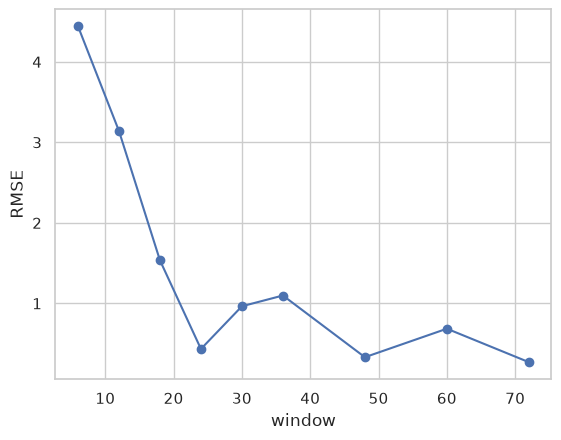

In [52]:
window = [6, 12, 18, 24, 30, 36, 48, 60, 72]
s_y = pd.Series(y)
rmse = {}
index = 0

for w in window:
    ma = s_y.rolling(w, center=True).mean()
    valid = ma.notna()
    rmse[w] = float(np.sqrt(np.mean((ma[valid].values - true_trend[valid.values]) ** 2)))
    print(f'Window {w} : {rmse[w]}')

plt.plot(rmse.keys(), rmse.values())
plt.scatter(rmse.keys(), rmse.values())
plt.xlabel('window')
plt.ylabel('RMSE')
plt.show()

In [56]:
best_w = min(window, key=lambda w: rmse[w])
rmse_w24 = rmse[24]
rmse_w30 = rmse[30]

**Autoverificare**

In [57]:
check_value("best_w", best_w, "72100ce9", "argmin al RMSE fa\u021b\u0103 de true_trend")
check_value("rmse_w24", rmse_w24, "6d49251b", "fereastra 24")
check_value("rmse_w30", rmse_w30, "bf5fac6e", "fereastra 30")
check("o fereastră de 30 este mai slabă decât una de 24", rmse_w30 > rmse_w24, "30 nu este multiplu al perioadei")

✅ best_w
✅ rmse_w24
✅ rmse_w30
✅ o fereastră de 30 este mai slabă decât una de 24


**Interpretarea voastră:** _scrieți aici_

## 2.3 · Diferențierea: cât costă  ★★☆

* `ys = pd.Series(y)` (de la 2.1). `d = ys.diff(24).diff(1)`: `n_lost` – câte eșantioane sunt `NaN`;
* `wn = pd.Series(np.random.default_rng(8).normal(size=4000))`: `vr1 = wn.diff().var() / wn.var()` și `vr2 = wn.diff().diff().var() / wn.var()`;
* `std_d24` – abaterea standard a lui `ys.diff(24)` (doar lag 24).

**Gândiți:** după o diferență cu lag 24, seria și-a pierdut ciclul *și* zgomotul ei este mai mare decât cel al lui `y` de √2 ori. Există o cale de a elimina ciclul fără a amplifica zgomotul? (Indiciu: STL / medii glisante.)

In [61]:
ys = pd.Series(y)

d = ys.diff(24).diff(1)
n_lost = int(d.isna().sum())

wn = pd.Series(np.random.default_rng(8).normal(size=4000))
vr1 = float(wn.diff().var() / wn.var())
vr2 = float(wn.diff().diff().var() / wn.var())
std_d24 = float(ys.diff(24).std())

**Autoverificare**

In [62]:
check_value("n_lost", n_lost, "89b235c0", "24 + 1")
check_value("vr1", vr1, "daa2edbf", "var(diff) / var")
check_value("vr2", vr2, "114662d4", "var(diff(diff)) / var")
check_value("std_d24", std_d24, "f78ecd3b", "std al lui y.diff(24)")

✅ n_lost
✅ vr1
✅ vr2
✅ std_d24


**Interpretarea voastră:** _scrieți aici_

## 2.4 · Frecvența de tăiere a unui trece-sus pentru eliminarea tendinței  ★★☆

Pentru `fc` în `1/200`, `1/72`, `1/30` construiți un trece-sus Butterworth de ordin 3 (`signal.butter(3, fc, 'high', fs=1.0, output='sos')`) și măsurați **câștigul lui la frecvența zilnică 1/24** cu `gain_db(sos, 1/24, 1.0)`.

* `g200`, `g72`, `g30` – cele trei câștiguri (dB);
* `period_best` – **perioada în ore (1/fc)** a *celei mai mari* frecvențe de tăiere al cărei câștig la frecvența zilnică este mai bun de −0.5 dB.

**Gândiți:** de ce vrem frecvența de tăiere cât mai mare, păstrând totuși ciclul zilnic? (Ce face aceasta cu tendința lentă și cu marginile?)

In [68]:
periods = [200, 72, 30]
gains = {}

for p in periods:
    fc = 1.0 / p
    sos = signal.butter(3, fc, btype="high", fs=1.0, output="sos")
    gains[p] = float(gain_db(sos, 1.0 / 24.0, 1.0))

In [70]:
g200 = gains[200]
g72 = gains[72]
g30 = gains[30]
period_best = min(p for p in periods if gains[p] > -0.5)

**Autoverificare**

In [71]:
check_value("g200", g200, "19524fce", "gain_db(sos, 1/24, 1.0)")
check_value("g72", g72, "39ccca44", "gain_db(sos, 1/24, 1.0)")
check_value("g30", g30, "e01d0d29", "gain_db(sos, 1/24, 1.0)")
check_value("period_best", period_best, "72100ce9", "cea mai mare frecven\u021b\u0103 de t\u0103iere (cea mai mic\u0103 perioad\u0103) care p\u0103streaz\u0103 ciclul zilnic \u00een limita a \u22120.5 dB")

✅ g200
✅ g72
✅ g30
✅ period_best


**Interpretarea voastră:** _scrieți aici_

## 2.5 · Eliminăm tendința sau diferențiem?  ★★★

`trend_stat, walk = make_walks(9)`. Ajutorul pentru reziduul dreptei este `resid = lambda v: v - np.polynomial.Polynomial.fit(np.arange(len(v)), v, 1)(np.arange(len(v)))`. Calculați **valoarea p ADF** (`adfuller(v, autolag="AIC")[1]`):

* `p_line_trend` – pentru `resid(trend_stat)`;
* `p_line_walk` – pentru `resid(walk)`;
* `p_diff_walk` – pentru `np.diff(walk)`.

**Scrieți** ce concluzionați despre tratamentul potrivit al fiecăreia dintre cele două serii.

In [74]:
trend_stat, walk = make_walks(9)
resid = lambda v: v - np.polynomial.Polynomial.fit(np.arange(len(v)), v, 1)(np.arange(len(v)))

p_line_trend = float(adfuller(resid(trend_stat), autolag="AIC")[1])
p_line_walk = float(adfuller(resid(walk), autolag="AIC")[1])
p_diff_walk = float(adfuller(np.diff(walk), autolag="AIC")[1])

**Autoverificare**

In [75]:
check("tendință + zgomot: după eliminarea dreptei seria este staționară (p < 0.05)", p_line_trend < 0.05, "adfuller(...)[1] pe reziduul dreptei")
check("mers aleator: după eliminarea dreptei NU este încă staționar (p > 0.05)", p_line_walk > 0.05, "o dreaptă nu face staționar un mers aleator")
check("mers aleator: o diferență îl face staționar", p_diff_walk < 0.05, "diferențiați o dată, apoi adfuller")

✅ tendință + zgomot: după eliminarea dreptei seria este staționară (p < 0.05)
✅ mers aleator: după eliminarea dreptei NU este încă staționar (p > 0.05)
✅ mers aleator: o diferență îl face staționar


**Interpretarea voastră:** _scrieți aici_

## 2.6 · Date reale (trafic): ce lag sezonier?  ★★☆

Folosiți seria de trafic din ianuarie–septembrie 2018 (`vol` de la 1.10).

* `std_lag24`, `std_lag168` – abaterile standard ale lui `vol.diff(24)` și `vol.diff(168)`; `best_lag` – lagul cu valoarea mai mică;
* `res = STL(vol, period=24, seasonal=7, robust=True).fit()`; `seasonal_strength = max(0, 1 - res.resid.var() / (res.seasonal + res.resid).var())`.

**Gândiți:** STL zilnic lasă tiparul săptămânal în rest. Propuneți o a doua componentă sezonieră și locul din `statsmodels` unde ați putea-o modela (indiciu: `MSTL`).

In [77]:
std_lag24 = float(vol.diff(24).std())
std_lag168 = float(vol.diff(168).std())

best_lag = 24 if std_lag24 < std_lag168 else 168

res = STL(vol, period=24, seasonal=7, robust=True).fit()
seasonal_strength = float(max(0.0, 1.0 - res.resid.var() / (res.seasonal + res.resid).var()))

**Autoverificare**

In [78]:
check_value("std_lag24", std_lag24, "e332bf43", "vol.diff(24).std()")
check_value("std_lag168", std_lag168, "8988cff8", "vol.diff(168).std()")
check_value("best_lag", best_lag, "c0367b98", "lagul cu std mai mic")
check_value("seasonal_strength", seasonal_strength, "1d464f4e", "1 - var(resid)/var(seasonal+resid) din STL(period=24, robust=True)")

✅ std_lag24
✅ std_lag168
✅ best_lag
✅ seasonal_strength


**Interpretarea voastră:** _scrieți aici_

## 2.7 · Date reale (EEG): o linie de bază de 5 minute  ★★☆

`eeg = pd.read_csv("sleepy_driver_eeg_data.csv")`; `ld = np.log10(eeg["delta"])` (1 eșantion/s).

* `base = ld.rolling(301, center=True, min_periods=1).median()`; `detr_std = (ld - base).std()`;
* `hp_std` – abaterea standard a ieșirii unui **trece-sus de ordin 2 la 1/300 Hz** (`sosfiltfilt`, `fs=1.0`).

**Gândiți:** o fereastră mai scurtă (de exemplu 21 s) ar da un `detr_std` *mai mic*. De ce nu este acesta un motiv să o alegeți?

In [94]:
eeg = pd.read_csv("sleepy_driver_eeg_data.csv")
ld = np.log10(eeg["delta"])

base = ld.rolling(301, center=True, min_periods=1).median()
sos_hp = signal.butter(N=2, Wn=1 / 300, btype="highpass", fs=1.0, output="sos")
hp_out = signal.sosfiltfilt(sos_hp, ld.values)

In [95]:
eeg.head(n=5)

,attention,meditation,delta,theta,lowAlpha,highAlpha,lowBeta,highBeta,lowGamma,highGamma,classification
0,26,34,960462,277180,26575,27356,26575,13056,9126,2683,0
1,29,54,39145,28225,20172,39551,20172,9933,5237,4750,0
2,40,48,75410,43144,8601,13564,8601,11663,2515,3251,0
3,66,47,16057,41211,2534,34254,2534,27663,11396,2825,0
4,81,67,10304,47239,33158,47349,33158,16328,5298,5471,0


In [96]:
detr_std = float((ld - base).std())
hp_std = float(np.std(hp_out))

**Autoverificare**

In [97]:
check_value("detr_std", detr_std, "6669743c", "std al lui ld - mediana glisant\u0103")
check_value("hp_std", hp_std, "a8db99af", "std al ie\u0219irii trece-susului")
check("ambele linii de bază elimină cea mai mare parte din varianța lentă", detr_std < ld.std() and hp_std < ld.std(), "seria fără tendință trebuie să varieze mai puțin decât cea originală")

✅ detr_std
✅ hp_std
✅ ambele linii de bază elimină cea mai mare parte din varianța lentă


**Interpretarea voastră:** _scrieți aici_

# Partea 3 — Proiectarea interpolării

Reamintire: `limit`, `limit_area`, lungimea golului în raport cu perioada semnalului și *validarea prin mascarea valorilor cunoscute*.

## 3.1 · Recensământul golurilor (trafic, ianuarie–septembrie 2018)  ★☆☆

`tr` ca la 1.10. `vol18 = tr.loc["2018", "traffic_volume"].reindex(pd.date_range("2018-01-01", "2018-09-30 23:00", freq="h"))` (fișierul se termină la 30 septembrie; **nu** interpolați încă).

* `n_missing` – ore lipsă; `n_gaps` – numărul de goluri (secvențe de `NaN` consecutive); `longest_gap` – lungimea (ore) celui mai lung; `n_gaps_gt3` – golurile mai lungi de **3** ore.

**Gândiți:** fișierul spunea 48 204 de rânduri și nicio valoare lipsă. De ce au rămas golurile invizibile până la `reindex`?

In [105]:
idx = pd.date_range("2018-01-01", "2018-09-30 23:00", freq="h")
isna = vol18.isna()
groups = isna.ne(isna.shift()).cumsum()
gap_lengths = isna.groupby(groups).sum()
gap_lengths = gap_lengths[gap_lengths > 0] 

In [107]:
vol18 = tr.loc["2018", "traffic_volume"].reindex(idx)
n_missing = int(isna.sum())
n_gaps = int(len(gap_lengths))
longest_gap = int(gap_lengths.max())
n_gaps_gt3 = int((gap_lengths > 3).sum())

**Autoverificare**

In [108]:
check_value("n_missing", n_missing, "df644619", "isna().sum()")
check_value("n_gaps", n_gaps, "143dac93", "num\u0103rul de secven\u021be de NaN consecutive")
check_value("longest_gap", longest_gap, "017144e2", "cea mai lung\u0103 secven\u021b\u0103")
check_value("n_gaps_gt3", n_gaps_gt3, "cf9dcf6d", "goluri mai lungi de 3 ore")

✅ n_missing
✅ n_gaps
✅ longest_gap
✅ n_gaps_gt3


**Interpretarea voastră:** _scrieți aici_

## 3.2 · Ce metodă pentru ce gol?  ★★☆

`truth = make_wave(7)` – două sinusoide ascunse plus puțin zgomot (600 de eșantioane). Pentru `L` în `3, 10, 40` ascundeți `truth[300:300+L]`, completați cu fiecare metodă din exemplul rezolvat (`ffill`, `linear`, `cubic` = `CubicSpline`, `pchip` = `PchipInterpolator`, `akima` = `Akima1DInterpolator`) și calculați RMSE **pe eșantioanele ascunse**.

* `best_L3`, `best_L10` – **numele** metodei cu cel mai mic RMSE (ca șir de caractere, de exemplu `"linear"`; la egalitate, prima din lista de mai sus);
* `rmse_linear_L10` – RMSE al metodei liniare pentru `L = 10`;
* `min_L40` – cel mai mic RMSE dintre toate metodele pentru `L = 40`.

**Gândiți:** perioada sinusoidei lente este de 50 de eșantioane. Exprimați cel mai lung gol în care ați mai avea încredere ca fracțiune din perioadă.

In [113]:
from scipy.interpolate import CubicSpline, PchipInterpolator, Akima1DInterpolator

In [114]:
truth = make_wave(7)
methods = ["ffill", "linear", "cubic", "pchip", "akima"]

def fill(series, how):
    x = np.arange(len(series)); ok = series.notna().values
    ok = series.notna().values
    
    if how == "ffill":
        return series.ffill().values
    elif how == "linear":
        return np.interp(x, x[ok], series.values[ok])
    elif how == "cubic":
        return CubicSpline(x[ok], series.values[ok])(x)
    elif how == "pchip":
        return PchipInterpolator(x[ok], series.values[ok])(x)
    elif how == "akima":
        return Akima1DInterpolator(x[ok], series.values[ok])(x)
    raise ValueError(f"Metodă necunoscută: {how}")

results = {L: {} for L in [3, 10, 40]}

In [115]:
for L in [3, 10, 40]:
    s = pd.Series(truth, copy=True)
    s.iloc[300:300 + L] = np.nan
    for m in methods:
        pred = fill(s, m)
        rmse = float(np.sqrt(np.mean((pred[300:300 + L] - truth[300:300 + L]) ** 2)))
        results[L][m] = rmse

In [116]:
best_L3 = min(methods, key=lambda m: results[3][m])
best_L10 = min(methods, key=lambda m: results[10][m])
rmse_linear_L10 = results[10]["linear"]
min_L40 = min(results[40].values())

**Autoverificare**

In [117]:
check_value("best_L3", best_L3, "ce371d3c", "argmin al RMSE la L = 3")
check_value("best_L10", best_L10, "ce371d3c", "argmin al RMSE la L = 10")
check_value("rmse_linear_L10", rmse_linear_L10, "b7e2620d", "liniar, L = 10")
check("nicio metodă nu funcționează bine pentru un gol de 40 de eșantioane (cel mai bun RMSE > jumătate din abaterea standard)", min_L40 > 0.5 * truth.std(), "golul este aproape o perioadă întreagă")

✅ best_L3
✅ best_L10
✅ rmse_linear_L10
✅ nicio metodă nu funcționează bine pentru un gol de 40 de eșantioane (cel mai bun RMSE > jumătate din abaterea standard)


**Interpretarea voastră:** _scrieți aici_

## 3.3 · Cât de lung poate fi un gol pe care interpolarea liniară îl suportă?  ★★☆

Cu `truth` de la 3.2, pentru `L = 2, 3, …, 60` ascundeți `truth[300:300+L]` și completați liniar.

* `L_max_linear` – cel mai mare `L` pentru care RMSE pe eșantioanele ascunse este **încă ≤ 0.25 · truth.std()** (opriți-vă la primul `L` care încalcă condiția);
* `L_over_period` – `L_max_linear / 50` (perioada sinusoidei lente).

**Gândiți:** comparați cu regula practică din exemplul rezolvat („un sfert din perioada celei mai rapide componente”). Cea mai rapidă componentă de aici are perioada 13.

In [118]:
thresh = 0.25 * truth.std()
x = np.arange(len(truth))
L_max_linear = 0

for L in range(2, 61):
    mask = np.ones(len(truth), dtype=bool)
    mask[300:300 + L] = False
    
    pred = np.interp(x, x[mask], truth[mask])
    rmse = float(np.sqrt(np.mean((pred[300:300 + L] - truth[300:300 + L]) ** 2)))
    
    if rmse <= thresh:
        L_max_linear = L
    else:
        break 



In [119]:
L_over_period = float(L_max_linear / 50.0)

**Autoverificare**

In [120]:
check_value("L_max_linear", L_max_linear, "a8994a90", "cel mai mare L cu RMSE <= 0.25*std")
check_value("L_over_period", L_over_period, "0e1a3f94", "L_max_linear / 50")

✅ L_max_linear
✅ L_over_period


**Interpretarea voastră:** _scrieți aici_

## 3.4 · Depășirea (overshoot) splineului cubic  ★★☆

O treaptă: `xs = np.array([0,1,2,3,4,5,6,7.])`, `ys_ = np.array([0,0,0,0,10,10,10,10.])`, evaluată pe `xf = np.linspace(0, 7, 300)`.

* `overshoot_cubic` = maximul lui `CubicSpline(xs, ys_)(xf)` − 10; `undershoot_cubic` = 0 − minimul lui;
* `pchip_ok` – `True` dacă interpolantul PCHIP rămâne în `[0, 10]` (folosiți o toleranță de 1e-9); `lin_ok` – același lucru pentru `np.interp`.

**Gândiți:** care dintre aceste mărimi din datele reale (numărători, umiditate, ocupare) nu pot fi niciodată negative? Ce ar face splineul după un salt brusc la zero?

In [121]:
xs = np.array([0, 1, 2, 3, 4, 5, 6, 7.0])
ys_ = np.array([0, 0, 0, 0, 10, 10, 10, 10.0])
xf = np.linspace(0, 7, 300)

y_cubic = CubicSpline(xs, ys_)(xf)
y_pchip = PchipInterpolator(xs, ys_)(xf)
y_lin = np.interp(xf, xs, ys_)

overshoot_cubic = float(np.max(y_cubic) - 10.0)
undershoot_cubic = float(0.0 - np.min(y_cubic))

tol = 1e-9
pchip_ok = bool((np.min(y_pchip) >= 0.0 - tol) and (np.max(y_pchip) <= 10.0 + tol))  
lin_ok = bool((np.min(y_lin) >= 0.0 - tol) and (np.max(y_lin) <= 10.0 + tol))

**Autoverificare**

In [122]:
check_value("overshoot_cubic", overshoot_cubic, "28b478ce", "maximul splineului minus 10")
check_value("undershoot_cubic", undershoot_cubic, "28b478ce", "0 minus minimul splineului")
check("PCHIP rămâne în domeniul datelor [0, 10]", pchip_ok, "PchipInterpolator este monoton între puncte")
check("liniarul rămâne în domeniul datelor", lin_ok, "np.interp nu iese niciodată din domeniu")

✅ overshoot_cubic
✅ undershoot_cubic
✅ PCHIP rămâne în domeniul datelor [0, 10]
✅ liniarul rămâne în domeniul datelor


**Interpretarea voastră:** _scrieți aici_

## 3.5 · Momente de timp neregulate  ★★☆

```python
idx = pd.to_datetime(["2026-01-01 00:00", "2026-01-01 00:20", "2026-01-01 01:40", "2026-01-01 01:50"])
s = pd.Series([5.0, np.nan, 35.0, 40.0], index=idx)
```

* `v_time` – valoarea de la 00:20 dată de `s.interpolate("time")`; `v_pos` – cea dată de `s.interpolate("linear")`.

**Gândiți:** care este cea corectă și cu cât greșește cealaltă? Când coincid cele două?

In [123]:
idx = pd.to_datetime(["2026-01-01 00:00", "2026-01-01 00:20", "2026-01-01 01:40", "2026-01-01 01:50"])
s = pd.Series([5.0, np.nan, 35.0, 40.0], index=idx)

In [124]:
v_time = float(s.interpolate("time").iloc[1])
v_pos = float(s.interpolate("linear").iloc[1])

**Autoverificare**

In [125]:
check_value("v_time", v_time, "c6fffb51", "interpolate(\"time\")")
check_value("v_pos", v_pos, "b9e68997", "interpolate(\"linear\")")
check("rezultatele după poziție și după timp diferă", abs(v_time - v_pos) > 1, "momentele de timp nu sunt echidistante")

✅ v_time
✅ v_pos
✅ rezultatele după poziție și după timp diferă


**Interpretarea voastră:** _scrieți aici_

## 3.6 · Date reale (trafic): validare prin mascare  ★★★

Folosiți `vol17 = tr.loc["2017", "traffic_volume"].reindex(pd.date_range("2017-01-01", "2017-12-31 23:00", freq="h"))` (cele 47 de ore lipsă reale rămân `NaN` și nu sunt niciodată evaluate).

Două experimente, ambele evaluate **doar pe pozițiile mascate a căror valoare adevărată există**:

* **izolate:** mascați 10 % din orele cunoscute alese prin `rng = np.random.default_rng(0); pos = rng.choice(np.flatnonzero(vol17.notna().values), size=int(0.10 * vol17.notna().sum()), replace=False)`;
* **bloc:** mascați cele 6 ore de la `2017-06-14 08:00`.

Metode: `"linear"` (`interpolate("linear")`), `"pchip"`, `"yesterday"` (`s.fillna(s.shift(24)).interpolate("linear")`), `"last_week"` (`shift(168)`, apoi liniar), `"ffill"`.

* `best_iso`, `rmse_best_iso`, `best_block`, `rmse_best_block` (nume ca șiruri de caractere; la egalitate → prima din lista de mai sus).

**Gândiți:** ce proprietate a golului decide între o metodă *netedă* și o *copie sezonieră*? Ce ați alege pentru un gol de 3 zile?

In [129]:
vol17 = tr.loc["2017", "traffic_volume"].reindex(pd.date_range("2017-01-01", "2017-12-31 23:00", freq="h"))
methods = ["linear", "pchip", "yesterday", "last_week", "ffill"]

def evaluate(positions):
    "returnează un dicționar {metodă: RMSE pe pozițiile mascate care au o valoare adevărată}"
    pos = np.asarray(positions)

    valid_pos = pos[vol17.iloc[pos].notna().values]
    truth = vol17.iloc[valid_pos].values

    s = vol17.copy()
    s.iloc[valid_pos] = np.nan

    filled = {
        "linear": s.interpolate("linear"),
        "pchip": s.interpolate("pchip"),
        "yesterday": s.fillna(s.shift(24)).interpolate("linear"),
        "last_week": s.fillna(s.shift(168)).interpolate("linear"),
        "ffill": s.ffill().bfill(),
    }

    scores = {}
    for m in methods:
        pred = filled[m].iloc[valid_pos].values
        scores[m] = float(np.sqrt(np.mean((pred - truth) ** 2)))
    return scores
    

In [134]:
rng = np.random.default_rng(0)
pos_iso = rng.choice(
    np.flatnonzero(vol17.notna().values),
    size=int(0.10 * vol17.notna().sum()),
    replace=False,
)
start_idx = vol17.index.get_loc(pd.Timestamp("2017-06-14 08:00"))
pos_block = np.arange(start_idx, start_idx + 6)
res_block = evaluate(pos_block)
res_iso = evaluate(pos_iso)
best_iso = min(methods, key=lambda m: res_iso[m])
rmse_best_iso = res_iso[best_iso]

In [135]:
best_block = min(methods, key=lambda m: res_block[m])
rmse_best_block = res_block[best_block]

**Autoverificare**

In [136]:
check_value("best_iso", best_iso, "a6e88a50", "metoda cu cel mai mic RMSE pe cele 10 % ore izolate")
check_value("rmse_best_iso", rmse_best_iso, "924b2af7", "RMSE-ul ei (rotunjit)")
check_value("best_block", best_block, "9523d9fb", "metoda cu cel mai mic RMSE pe blocul de 6 ore")
check_value("rmse_best_block", rmse_best_block, "57664b7f", "RMSE-ul ei")
check("pentru bloc câștigă o altă metodă decât pentru orele izolate", best_iso != best_block, "cea mai bună metodă depinde de lungimea golului")

✅ best_iso
✅ rmse_best_iso
✅ best_block
✅ rmse_best_block
✅ pentru bloc câștigă o altă metodă decât pentru orele izolate


**Interpretarea voastră:** _scrieți aici_

## 3.7 · Date reale (birou inteligent): trei moduri de a completa 31 de minute  ★★★

`office = pd.read_csv("smart_office_dataset.csv", parse_dates=["timestamp"], index_col="timestamp")`. Ascundeți `temp_c` de la `2026-03-03 10:20` la `10:50` (inclusiv; valorile adevărate sunt `truth_blk`). Completați-le cu

* `"linear"` – `interpolate("linear")`;
* `"knn1"` – `KNNImputer(n_neighbors=5).fit_transform(art[["temp_c"]])`;
* `"yesterday"` – `office["temp_c"].shift(1440)` la aceleași minute.

* `rmse_linear`, `rmse_knn1`, `rmse_yesterday` și `best_office_method` (șir de caractere).

**Gândiți:** de ce este `KNNImputer` pe o singură coloană o idee proastă? Ce ați adăuga ca să devină util?

In [137]:
office = pd.read_csv("smart_office_dataset.csv", parse_dates=["timestamp"], index_col="timestamp")
sl = slice("2026-03-03 10:20", "2026-03-03 10:50")

truth_blk = office.loc[sl, "temp_c"].values
art = office[["temp_c"]].copy()
art.loc[sl, "temp_c"] = np.nan
pred_linear = art["temp_c"].interpolate("linear").loc[sl].values
rmse_linear = float(np.sqrt(np.mean((pred_linear - truth_blk) ** 2)))

knn_filled = KNNImputer(n_neighbors=5).fit_transform(art[["temp_c"]])
pred_knn1 = pd.Series(knn_filled[:, 0], index=art.index).loc[sl].values
rmse_knn1 = float(np.sqrt(np.mean((pred_knn1 - truth_blk) ** 2)))

pred_yesterday = office["temp_c"].shift(1440).loc[sl].values
rmse_yesterday = float(np.sqrt(np.mean((pred_yesterday - truth_blk) ** 2)))

scores = {
    "linear": rmse_linear,
    "knn1": rmse_knn1,
    "yesterday": rmse_yesterday,
}

best_office_method = min(scores, key=scores.get)

**Autoverificare**

In [138]:
check_value("rmse_linear", rmse_linear, "37587849", "RMSE al metodei liniare pe cele 31 de minute ascunse")
check_value("rmse_knn1", rmse_knn1, "9964c8ae", "KNNImputer pe o singur\u0103 coloan\u0103")
check_value("rmse_yesterday", rmse_yesterday, "0e1a3f94", "valoarea aceluia\u0219i minut din ziua precedent\u0103")
check_value("best_office_method", best_office_method, "7f2fe580", "\"linear\", \"knn1\" sau \"yesterday\"")
check("KNN pe o singură coloană este cel mai slab dintre cele trei", rmse_knn1 > max(rmse_linear, rmse_yesterday), "cu o singură coloană imputer-ul returnează media coloanei")

✅ rmse_linear
✅ rmse_knn1
✅ rmse_yesterday
✅ best_office_method
✅ KNN pe o singură coloană este cel mai slab dintre cele trei


**Interpretarea voastră:** _scrieți aici_

# Partea 4 — Proiectarea detectorului de valori aberante

`prf(flag, truth)` (furnizată) returnează `(precizie, recall, F1)` pentru o detecție booleană față de un adevăr boolean. Reguli disponibile în caietul de exemple: scorul z, scorul z modificat (MAD), IQR, Hampel, Isolation Forest, DBSCAN.

## 4.1 · Pragul scorului z  ★☆☆

`v, truth = make_values(31, frac=0.02)` (1000 de valori, 2 % valori aberante plantate).

* `n_flag_k2`, `n_flag_k3`, `n_flag_k4` – numărul de valori cu `|v − media| / std > k`;
* `k_best` – dintre `[2, 2.5, 3, 3.5, 4]`, valoarea `k` cu cel mai mare F1 (`prf`), prima la egalitate.

**Gândiți:** pentru un eșantion *normal* de 1000 de valori, câte alarme false vă așteptați la k = 2 și la k = 3? Concordă tabelul?

In [140]:
v, truth = make_values(31, frac=0.02)
z = np.abs(v - np.mean(v)) / np.std(v)

n_flag_k2 = int((z > 2).sum())
n_flag_k3 = int((z > 3).sum())
n_flag_k4 = int((z > 4).sum())


ks = [2, 2.5, 3, 3.5, 4]
f1_scores = {k: prf(z > k, truth)[2] for k in ks}
k_best = max(ks, key=lambda k: f1_scores[k])

**Autoverificare**

In [141]:
check_value("n_flag_k2", n_flag_k2, "35e594c4", "(abs(v - mean)/std > 2).sum()")
check_value("n_flag_k3", n_flag_k3, "b9e68997", "k = 3")
check_value("n_flag_k4", n_flag_k4, "b9e68997", "k = 4")
check_value("k_best", k_best, "853a9a75", "valoarea k cu cel mai mare F1 dintre [2, 2.5, 3, 3.5, 4]")

✅ n_flag_k2
✅ n_flag_k3
✅ n_flag_k4
✅ k_best


**Interpretarea voastră:** _scrieți aici_

## 4.2 · Mascarea  ★★☆

`v2, truth2 = make_values(32, frac=0.20)` – acum **20 %** dintre valori sunt aberante.

* `std_inflation = v2.std() / v2[~truth2].std()` – cât umflă valorile aberante abaterea standard;
* `recall_z3` – recall-ul regulii `|v − media| / std > 3`; `recall_mad` – recall-ul scorului z modificat `0.6745·|v − mediana| / MAD > 3.5` (`MAD = mediana(|v − mediana|)`).

**Gândiți:** pe care dintre cele două reguli ați folosi-o dacă nu ați avea nicio idee despre contaminare și de ce „rezistă” mediana, în timp ce media nu?

In [142]:
v2, truth2 = make_values(32, frac=0.20)
z_classic = np.abs(v2 - np.mean(v2)) / np.std(v2)
med = np.median(v2)
mad = np.median(np.abs(v2 - med))
z_mod = 0.6745 * np.abs(v2 - med) / mad

In [143]:
std_inflation = float(v2.std() / v2[~truth2].std())
recall_z3 = float(prf(z_classic > 3, truth2)[1])
recall_mad = float(prf(z_mod > 3.5, truth2)[1])

**Autoverificare**

In [144]:
check_value("std_inflation", std_inflation, "120689d4", "v.std() / v[~truth].std()")
check_value("recall_z3", recall_z3, "561b2814", "recall-ul lui z > 3")
check_value("recall_mad", recall_mad, "cf9dcf6d", "recall-ul scorului z modificat > 3.5")
check("MAD găsește mai multe valori aberante decât scorul z", recall_mad > recall_z3, "mascare")

✅ std_inflation
✅ recall_z3
✅ recall_mad
✅ MAD găsește mai multe valori aberante decât scorul z


**Interpretarea voastră:** _scrieți aici_

## 4.3 · Date asimetrice  ★★☆

`sk = np.random.default_rng(33).lognormal(mean=3, sigma=0.7, size=2000)`. Regula IQR marchează `v < Q1 − 1.5·IQR` sau `v > Q3 + 1.5·IQR`.

* `n_iqr_raw`, `n_iqr_log` – numărul de valori marcate pe `sk` și pe `np.log(sk)`;
* `skew_raw`, `skew_log` – `scipy.stats.skew` pentru cele două.

**Gândiți:** în `sk` nu există *nicio* defecțiune. Care dintre cele două numere este un număr de alarme false?

In [145]:
sk = np.random.default_rng(33).lognormal(mean=3, sigma=0.7, size=2000)

def count_iqr_outliers(arr):
    q1, q3 = np.percentile(arr, [25, 75])
    iqr = q3 - q1
    return int(((arr < q1 - 1.5 * iqr) | (arr > q3 + 1.5 * iqr)).sum())

log_sk = np.log(sk)

In [146]:
n_iqr_raw = count_iqr_outliers(sk)
n_iqr_log = count_iqr_outliers(log_sk)
skew_raw = float(stats.skew(sk))
skew_log = float(stats.skew(log_sk))

**Autoverificare**

In [147]:
check_value("n_iqr_raw", n_iqr_raw, "1ab94840", "regula IQR cu c = 1.5 pe valorile brute")
check_value("n_iqr_log", n_iqr_log, "a8994a90", "aceea\u0219i regul\u0103 pe logaritm")
check_value("skew_raw", skew_raw, "7e88bc95", "scipy.stats.skew")
check_value("skew_log", skew_log, "91539d74", "scipy.stats.skew al logaritmului")

✅ n_iqr_raw
✅ n_iqr_log
✅ skew_raw
✅ skew_log


**Interpretarea voastră:** _scrieți aici_

## 4.4 · Fereastra Hampel  ★★☆

`ts, truth = make_level_series(34)` – un nivel cu variație lentă și 25 de valori aberante plantate. Folosiți `hampel(ts, window, n_sigmas)` (furnizată) cu `n_sigmas = 4` și ferestrele `[5, 11, 21, 51, 101, 301]`.

* `best_window` – fereastra cu cel mai mare F1 (prima la egalitate); `f1_best`;
* `f1_global` – F1 al regulii globale `|ts − media| / std > 3`.

**Gândiți:** de ce crește F1 mai întâi și apoi scade cu fereastra? Schițați cum arată fiecare tip de eșec.

In [149]:
ts, truth = make_level_series(34)
windows = [5, 11, 21, 51, 101, 301]

f1_scores = {}
for w in windows:
    res = hampel(ts, w, n_sigmas=4)
    mask = res[1] if isinstance(res, tuple) else res
    f1_scores[w] = float(prf(mask, truth)[2])

z_global = np.abs(ts - np.mean(ts)) / np.std(ts)

In [150]:
best_window = max(windows, key=lambda w: f1_scores[w])
f1_best = f1_scores[best_window]
f1_global = float(prf(z_global > 3, truth)[2])

**Autoverificare**

In [151]:
check_value("best_window", best_window, "2e3bb484", "fereastra cu cel mai mare F1 (n_sigmas = 4)")
check_value("f1_best", f1_best, "b8cbc389", "F1-ul ei")
check_value("f1_global", f1_global, "561b2814", "F1 of |ts - mean| / std > 3")
check("regula glisantă bate regula globală pe un nivel în mișcare", f1_best > f1_global, "pragurile globale nu pot urmări nivelul")

✅ best_window
✅ f1_best
✅ f1_global
✅ regula glisantă bate regula globală pe un nivel în mișcare


**Interpretarea voastră:** _scrieți aici_

## 4.5 · Contaminarea Isolation Forest  ★★☆

`X2, truth2d = make_blobs2d(35)` (două clustere și 12 valori aberante printre 612 puncte).

Pentru `contamination` în `0.01, 0.05, 0.2` ajustați `IsolationForest(contamination=c, n_estimators=200, random_state=0)` și numărați rândurile cu `predict == -1`: `n_flag_c001`, `n_flag_c005`, `n_flag_c02`; `recall_c001` – recall-ul (față de `truth2d`) la 0.01.

**Gândiți:** modelul nu a văzut niciodată fracția reală de valori aberante. Cum ați alege contaminarea într-un proiect real? (indiciu: `score_samples`, cunoștințe din domeniu, validare pe defecțiuni etichetate).

In [153]:
X2, truth2d = make_blobs2d(35)

preds = {}
for c in [0.01, 0.05, 0.2]:
    clf = IsolationForest(contamination=c, n_estimators=200, random_state=0)
    preds[c] = (clf.fit_predict(X2) == -1)



In [154]:
n_flag_c001 = int(preds[0.01].sum())
n_flag_c005 = int(preds[0.05].sum())
n_flag_c02 = int(preds[0.2].sum())
recall_c001 = float(prf(preds[0.01], truth2d)[1])

**Autoverificare**

In [155]:
check_value("n_flag_c001", n_flag_c001, "b2337ecb", "predict(X) == -1, contamination 0.01")
check_value("n_flag_c005", n_flag_c005, "d4ea6b9f", "contamination 0.05")
check_value("n_flag_c02", n_flag_c02, "c1be4f9d", "contamination 0.2")
check_value("recall_c001", recall_c001, "16ad1c0b", "recall-ul valorilor aberante plantate la contamination 0.01")
check("marcarea a 20 % dintre rânduri este mult mai mult decât valorile aberante reale", n_flag_c02 > 5 * truth2d.sum(), "contamination este un parametru al utilizatorului")

✅ n_flag_c001
✅ n_flag_c005
✅ n_flag_c02
✅ recall_c001
✅ marcarea a 20 % dintre rânduri este mult mai mult decât valorile aberante reale


**Interpretarea voastră:** _scrieți aici_

## 4.6 · DBSCAN: scalarea și eps  ★★★

`X3, truth3 = make_blobs2d(36, unit2=100)` – a doua trăsătură este exprimată în unități de 100 de ori mai mari.

* `n_noise_unscaled` – numărul de puncte etichetate `-1` de `DBSCAN(eps=0.35, min_samples=5)` pe `X3` așa cum este;
* `n_noise_scaled` – același lucru pe `StandardScaler().fit_transform(X3)`;
* `best_eps` – pe datele **scalate**, valoarea `eps` din `[0.1, 0.2, 0.35, 0.6, 1.0]` care maximizează F1 pentru `labels == -1` față de `truth3` (prima la egalitate).

**Gândiți:** de ce este rezultatul nescalat inutil? Care este efectul lui `min_samples`? Desenați curba distanțelor la al 5-lea vecin și căutați cotul.

In [156]:
X3, truth3 = make_blobs2d(36, unit2=100)
Xs3 = StandardScaler().fit_transform(X3)

labels_unscaled = DBSCAN(eps=0.35, min_samples=5).fit_predict(X3)
labels_scaled = DBSCAN(eps=0.35, min_samples=5).fit_predict(Xs3)

eps_list = [0.1, 0.2, 0.35, 0.6, 1.0]
f1_scores = {}
for eps in eps_list:
    pred = (DBSCAN(eps=eps, min_samples=5).fit_predict(Xs3) == -1)
    f1_scores[eps] = float(prf(pred, truth3)[2])

In [157]:
n_noise_unscaled = int((labels_unscaled == -1).sum())
n_noise_scaled = int((labels_scaled == -1).sum())
best_eps = max(eps_list, key=lambda e: f1_scores[e])

**Autoverificare**

In [158]:
check_value("n_noise_scaled", n_noise_scaled, "b2337ecb", "DBSCAN(eps=0.35, min_samples=5) pe date standardizate")
check_value("n_noise_unscaled", n_noise_unscaled, "3a3409bf", "acela\u0219i lucru pe datele brute \u00een care tr\u0103s\u0103tura 2 este \u00eenmul\u021bit\u0103 cu 100")
check_value("best_eps", best_eps, "a976726b", "eps cu cel mai mare F1 dintre [0.1, 0.2, 0.35, 0.6, 1.0]")

✅ n_noise_scaled
✅ n_noise_unscaled
✅ best_eps


**Interpretarea voastră:** _scrieți aici_

## 4.7 · Date reale (birou inteligent): reguli față de statistică  ★★☆

`co2 = office["co2_ppm"].interpolate()`.

* `n_rule` – valorile din `office["co2_ppm"]` sub 300 sau peste 1500 ppm;
* `n_hampel_floor3`, `n_hampel_floor8` – valorile marcate de `hampel(co2, 15, 5, floor)` cu `floor = 3` și `floor = 8`;
* `n_temp_neg` – numărul de eșantioane cu `temp_c < 0`.

**Gândiți:** pragul minim 3 marchează mult mai multe valori decât 8. Priviți *unde* se află valorile în plus (orele liniștite ale nopții?) și explicați într-o propoziție ce reprezintă pragul minim.

In [159]:
co2 = office["co2_ppm"].interpolate()

n_rule = int(((office["co2_ppm"] < 300) | (office["co2_ppm"] > 1500)).sum())

res3 = hampel(co2, 15, 5, 3)
mask3 = res3[1] if isinstance(res3, tuple) else res3
n_hampel_floor3 = int(np.sum(mask3))

res8 = hampel(co2, 15, 5, 8)
mask8 = res8[1] if isinstance(res8, tuple) else res8
n_hampel_floor8 = int(np.sum(mask8))

n_temp_neg = int((office["temp_c"] < 0).sum())

**Autoverificare**

In [160]:
check_value("n_rule", n_rule, "017144e2", "valori sub 300 sau peste 1500")
check_value("n_hampel_floor3", n_hampel_floor3, "b9e68997", "fereastra 15, 5 sigma, prag minim 3")
check_value("n_hampel_floor8", n_hampel_floor8, "017144e2", "fereastra 15, 5 sigma, prag minim 8")
check_value("n_temp_neg", n_temp_neg, "017144e2", "temp_c < 0")

✅ n_rule
✅ n_hampel_floor3
✅ n_hampel_floor8
✅ n_temp_neg


**Interpretarea voastră:** _scrieți aici_

## 4.8 · Date reale (fișierul de trafic): o regulă fizică este suficientă  ★☆☆

`raw = pd.read_csv("Metro_Interstate_Traffic_Volume.csv")` (toate cele 48 204 de rânduri, fără eliminarea duplicatelor).

* `n_temp_zero` – rânduri cu `temp == 0` (Kelvin: zero absolut este imposibil);
* `rain_max`, `rain_second` – cea mai mare și a doua cea mai mare valoare din `rain_1h`;
* `n_rain_above_100` – rânduri cu `rain_1h > 100` mm într-o oră.

**Gândiți:** recordul de precipitații într-o oră pe Pământ este de aproximativ 305 mm. Ce faceți cu fiecare dintre aceste valori: eliminați, limitați sau păstrați? Scrieți regula pe care ați pune-o în pipeline.

In [161]:
raw = pd.read_csv("Metro_Interstate_Traffic_Volume.csv")
top2_rain = raw["rain_1h"].nlargest(2).values

In [162]:
n_temp_zero = int((raw["temp"] == 0).sum())
rain_max = float(top2_rain[0])
rain_second = float(top2_rain[1])
n_rain_above_100 = int((raw["rain_1h"] > 100).sum())

**Autoverificare**

In [163]:
check_value("n_temp_zero", n_temp_zero, "a8994a90", "temp == 0 \u00een fi\u0219ierul de trafic")
check_value("rain_max", rain_max, "de7fea0b", "maximul lui rain_1h")
check_value("rain_second", rain_second, "ce31a0ea", "a doua cea mai mare valoare")
check_value("n_rain_above_100", n_rain_above_100, "cf9dcf6d", "r\u00e2nduri cu rain_1h > 100 mm")

✅ n_temp_zero
✅ rain_max
✅ rain_second
✅ n_rain_above_100


**Interpretarea voastră:** _scrieți aici_

# Partea 5 — Proiectarea reducerii dimensionalității

`make_latent(seed)` dă un tabel `X` cu 10 trăsături (unități foarte diferite) generate de **3 factori ascunși** și o etichetă `y` care depinde de primul factor.

## 5.1 · De ce scalăm înainte de PCA  ★☆☆

`X, y = make_latent(42, n=500)`.

* `pc1_raw` – raportul varianței explicate al primei componente a lui `PCA().fit(X)`; `pc1_std` – după `StandardScaler().fit_transform(X)`;
* `dominant_raw` – indexul (0–9) al trăsăturii cu cel mai mare `|loading|` pe prima componentă brută (`pca.components_[0]`).

**Gândiți:** ce trăsătură domină PCA brut și de ce? Poartă trăsătura dominantă *mai multă informație* sau doar *numere mai mari*?

In [164]:
X, y = make_latent(42, n=500)
pca_raw = PCA().fit(X)

X_std = StandardScaler().fit_transform(X)
pca_std = PCA().fit(X_std)

In [165]:
pc1_raw = float(pca_raw.explained_variance_ratio_[0])
pc1_std = float(pca_std.explained_variance_ratio_[0])
dominant_raw = int(np.argmax(np.abs(pca_raw.components_[0])))

**Autoverificare**

In [166]:
check_value("pc1_raw", pc1_raw, "faf3c000", "PCA().fit(X).explained_variance_ratio_[0]")
check_value("pc1_std", pc1_std, "26ccbcee", "acela\u0219i lucru dup\u0103 StandardScaler")
check_value("dominant_raw", dominant_raw, "b2337ecb", "indexul celui mai mare |loading| al lui PC1 pe datele brute")

✅ pc1_raw
✅ pc1_std
✅ dominant_raw


**Interpretarea voastră:** _scrieți aici_

## 5.2 · Câte componente?  ★★☆

Pe datele **standardizate** de la 5.1:

* `k_90` – cel mai mic număr de componente cu varianță explicată cumulată ≥ 0.90;
* `k_kaiser` – numărul de valori proprii (`explained_variance_`) mai mari ca 1;
* `k_parallel` – numărul de valori proprii mai mari decât valorile proprii **medii** ale PCA pe 50 de matrice normale aleatoare de aceeași formă (`np.random.default_rng(s).normal(size=Zs.shape)` pentru `s` în `range(50)`).

**Gândiți:** care regulă ar eșua dacă datele nu ar fi standardizate? Care cere o simulare?

In [167]:
Zs = StandardScaler().fit_transform(X)
pca = PCA().fit(Zs)

cum_var = np.cumsum(pca.explained_variance_ratio_)

rand_eigvals = np.array([
    PCA().fit(np.random.default_rng(s).normal(size=Zs.shape)).explained_variance_
    for s in range(50)
])
mean_rand_eigvals = rand_eigvals.mean(axis=0)

In [168]:
k_90 = int(np.searchsorted(cum_var, 0.90) + 1)

k_kaiser = int(np.sum(pca.explained_variance_ > 1.0))
k_parallel = int(np.sum(pca.explained_variance_ > mean_rand_eigvals))

**Autoverificare**

In [169]:
check_value("k_90", k_90, "a97491cd", "cel mai mic k cu varian\u021b\u0103 cumulat\u0103 >= 0.90")
check_value("k_kaiser", k_kaiser, "a97491cd", "num\u0103rul de valori proprii > 1")
check_value("k_parallel", k_parallel, "a97491cd", "valori proprii peste valorile proprii medii ale a 50 de matrice aleatoare")
check("regulile concordă între ele", k_90 == k_kaiser == k_parallel, "pe aceste date cele trei reguli ar trebui să dea același număr")

✅ k_90
✅ k_kaiser
✅ k_parallel
✅ regulile concordă între ele


**Interpretarea voastră:** _scrieți aici_

## 5.3 · Eroarea de reconstrucție  ★★☆

Pentru `k` în `1, 3, 6` ajustați `PCA(n_components=k)` pe `Zs`, proiectați și reconstruiți (`inverse_transform(transform(Zs))`); `rmse_kK` = `sqrt(medie((Zs − reconstrucție)²))`.

**Gândiți:** de ce nu ajunge eroarea la zero pentru `k = 3`, deși există doar 3 factori ascunși?

In [171]:
def reconstruction_rmse(Z, k):
    pca = PCA(n_components=k).fit(Z)
    Z_rec = pca.inverse_transform(pca.transform(Z))
    return float(np.sqrt(np.mean((Z - Z_rec) ** 2)))

In [172]:
rmse_k1 = reconstruction_rmse(Zs, 1)
rmse_k3 = reconstruction_rmse(Zs, 3)
rmse_k6 = reconstruction_rmse(Zs, 6)

**Autoverificare**

In [173]:
check_value("rmse_k1", rmse_k1, "ce5d3aa7", "PCA(k).fit(Zs), inverse_transform(transform(Zs))")
check_value("rmse_k3", rmse_k3, "358e553b", "k = 3")
check_value("rmse_k6", rmse_k6, "36819111", "k = 6")
check("eroarea scade mult până la k = 3 și puțin după aceea", (rmse_k1 - rmse_k3) > 3 * (rmse_k3 - rmse_k6), "cotul erorii de reconstrucție este la dimensiunea adevărată")

✅ rmse_k1
✅ rmse_k3
✅ rmse_k6
✅ eroarea scade mult până la k = 3 și puțin după aceea


**Interpretarea voastră:** _scrieți aici_

## 5.4 · Praguri de selecție  ★★☆

`Xq = X.copy(); Xq["const"] = 7.0; Xq["rare_flag"] = 1.0; Xq.loc[Xq.sample(5, random_state=0).index, "rare_flag"] = 0.0` (12 coloane).

* `n_const_raw` – coloanele păstrate de `VarianceThreshold(0.01)` pe `Xq`; `n_const_std` – după `StandardScaler().fit_transform(Xq)`;
* `n_kept_corr` – filtru de corelație pe cele **10 coloane originale** ale lui `X`: parcurgeți coloanele în ordine, păstrați o coloană dacă nu are `|r| > 0.9` cu o coloană deja păstrată (`X.corr().abs()`).

**Gândiți:** care dintre cele două praguri (brut/standardizat) a găsit coloanele inutile și de ce?

In [174]:
Xq = X.copy()
Xq["const"] = 7.0
Xq["rare_flag"] = 1.0
Xq.loc[Xq.sample(5, random_state=0).index, "rare_flag"] = 0.0

sel_raw = VarianceThreshold(threshold=0.01).fit(Xq)

Xq_std = StandardScaler().fit_transform(Xq)
sel_std = VarianceThreshold(threshold=0.01).fit(Xq_std)

corr_abs = X.corr().abs()
kept_cols = []
for col in X.columns:
    if not any(corr_abs.loc[col, k] > 0.9 for k in kept_cols):
        kept_cols.append(col)



In [175]:
n_const_raw = int(sel_raw.get_support().sum()) 
n_const_std = int(sel_std.get_support().sum())  
n_kept_corr = int(len(kept_cols))

**Autoverificare**

In [176]:
check_value("n_const_raw", n_const_raw, "a8994a90", "VarianceThreshold(0.01) pe tabelul brut: c\u00e2te coloane p\u0103streaz\u0103")
check_value("n_const_std", n_const_std, "c6fffb51", "acela\u0219i lucru dup\u0103 StandardScaler")
check_value("n_kept_corr", n_kept_corr, "017144e2", "filtru de corela\u021bie lacom, |r| > 0.9 pe cele 10 tr\u0103s\u0103turi originale")

✅ n_const_raw
✅ n_const_std
✅ n_kept_corr


**Interpretarea voastră:** _scrieți aici_

## 5.5 · Scurgerea de informație (leak)  ★★★

`Xn, yn = make_noise_task(51)` – 100 de rânduri, 500 de trăsături, **etichete aleatoare**: acuratețea adevărată a oricărui clasificator este 50 %. Folosiți `cv = KFold(5, shuffle=True, random_state=0)` și `LogisticRegression(max_iter=1000)`.

* `acc_leaky` – mai întâi selectați cele mai bune 10 trăsături cu `SelectKBest(f_classif, k=10)` pe **toate** datele, apoi validați încrucișat clasificatorul pe coloanele selectate;
* `acc_honest` – validați încrucișat `make_pipeline(StandardScaler(), SelectKBest(f_classif, k=10), LogisticRegression(max_iter=1000))` pe `Xn` întreg (selectorul este reajustat în fiecare fold).

**Scrieți** o propoziție care explică de ce `acc_leaky` este mult peste 0.5 deși etichetele sunt aleatoare.

In [177]:
Xn, yn = make_noise_task(51)
cv = KFold(5, shuffle=True, random_state=0)

X_sel = SelectKBest(f_classif, k=10).fit_transform(Xn, yn)
pipe_leaky = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

pipe_honest = make_pipeline(StandardScaler(), SelectKBest(f_classif, k=10), LogisticRegression(max_iter=1000),)

In [178]:
acc_leaky = float(cross_val_score(pipe_leaky, X_sel, yn, cv=cv, scoring="accuracy").mean())
acc_honest = float(cross_val_score(pipe_honest, Xn, yn, cv=cv, scoring="accuracy").mean())

**Autoverificare**

In [179]:
check("selecția în afara validării încrucișate arată bine pe zgomot pur (> 0.7)", acc_leaky > 0.7, "o scurgere: selectorul a văzut fold-urile de test")
check("pipeline-ul onest este la nivelul întâmplării (< 0.65)", acc_honest < 0.65, "etichetele sunt aleatoare")
check("scurgerea umflă acuratețea cu mai mult de 0.15", acc_leaky - acc_honest > 0.15, "estimare onestă = selectorul în interiorul pipeline-ului")

✅ selecția în afara validării încrucișate arată bine pe zgomot pur (> 0.7)
✅ pipeline-ul onest este la nivelul întâmplării (< 0.65)
✅ scurgerea umflă acuratețea cu mai mult de 0.15


**Interpretarea voastră:** _scrieți aici_

## 5.6 · Perplexitatea t-SNE  ★★☆

Pe `Zs` standardizat (500 × 10) calculați `TSNE(2, perplexity=p, random_state=0, init="pca").fit_transform(Zs)` pentru `p = 2` și `p = 30` și `trustworthiness(Zs, E, n_neighbors=10)`: `trust_2`, `trust_30`.

**Gândiți:** reprezentați grafic cele două încorporări colorate după `y`. Pe care ați arăta-o unui coleg? Ce concluzii despre *distanțele dintre clustere* nu sunt permise în niciuna?

In [180]:
E_2 = TSNE(n_components=2, perplexity=2, random_state=0, init="pca").fit_transform(Zs)
E_30 = TSNE(n_components=2, perplexity=30, random_state=0, init="pca").fit_transform(Zs)

In [181]:
trust_2 = float(trustworthiness(Zs, E_2, n_neighbors=10))
trust_30 = float(trustworthiness(Zs, E_30, n_neighbors=10))

**Autoverificare**

In [182]:
check("perplexitatea 30 păstrează vecinătățile (trustworthiness > 0.9)", trust_30 > 0.9, "TSNE(2, perplexity=30, random_state=0, init=\"pca\")")
check("perplexitatea 2 este mai slabă decât 30", trust_2 < trust_30, "o perplexitate prea mică rupe structura în insule")

✅ perplexitatea 30 păstrează vecinătățile (trustworthiness > 0.9)
✅ perplexitatea 2 este mai slabă decât 30


**Interpretarea voastră:** _scrieți aici_

## 5.7 · Date reale (EEG): PCA și evaluare onestă  ★★★

`eeg`, cu cele opt coloane de benzi `bands = ["delta","theta","lowAlpha","highAlpha","lowBeta","highBeta","lowGamma","highGamma"]`; `lg = np.log10(eeg[bands])`; `yE = eeg["classification"].values`.

* `pc1_log`, `k90_log` – primul raport al varianței explicate și numărul de componente pentru 90 % pe `StandardScaler().fit_transform(lg)`;
* `acc_contig` – acuratețea medie a lui `make_pipeline(StandardScaler(), PCA(n_components=2), LogisticRegression(max_iter=1000))` pe `lg`, cu `KFold(5, shuffle=False)`;
* `acc_shuffled` – același lucru cu `KFold(5, shuffle=True, random_state=0)`.

**Scrieți** ce vă spun aceste două acurateți și rata clasei majoritare despre utilizarea acestui set de date pentru un clasificator de somnolență.

In [183]:
bands = ["delta", "theta", "lowAlpha", "highAlpha", "lowBeta", "highBeta", "lowGamma", "highGamma"]
lg = np.log10(eeg[bands])
yE = eeg["classification"].values

lg_std = StandardScaler().fit_transform(lg)
pca_eeg = PCA().fit(lg_std)

pipe = make_pipeline(StandardScaler(), PCA(n_components=2), LogisticRegression(max_iter=1000))

In [184]:
pc1_log = float(pca_eeg.explained_variance_ratio_[0])
k90_log = int(np.searchsorted(np.cumsum(pca_eeg.explained_variance_ratio_), 0.90) + 1)
acc_contig = float(cross_val_score(pipe, lg, yE, cv=KFold(5, shuffle=False), scoring="accuracy").mean())
acc_shuffled = float(cross_val_score(pipe, lg, yE, cv=KFold(5, shuffle=True, random_state=0), scoring="accuracy").mean())

**Autoverificare**

In [185]:
check_value("pc1_log", pc1_log, "6fc7a7de", "explained_variance_ratio_[0] al PCA pe benzile log10 standardizate")
check_value("k90_log", k90_log, "9ae1524b", "componente pentru 90 % varian\u021b\u0103")
check("fold-urile amestecate arată mai bine decât cele contigue (o scurgere între secunde vecine)", acc_shuffled > acc_contig, "secundele vecine sunt aproape același eșantion")
check("acuratețea onestă (contiguă) nu este mai bună decât clasa majoritară", acc_contig <= max(yE.mean(), 1 - yE.mean()), "raportați baseline-ul lângă fiecare acuratețe")

✅ pc1_log
✅ k90_log
✅ fold-urile amestecate arată mai bine decât cele contigue (o scurgere între secunde vecine)
✅ acuratețea onestă (contiguă) nu este mai bună decât clasa majoritară


**Interpretarea voastră:** _scrieți aici_

# Partea 6 — Proiectarea detectorului de puncte de schimbare

Furnizate: `sigma_hat(v)` (nivel robust de zgomot din primele diferențe), `cusum_alarms(x, mu0, sigma, k, h)` și generatoarele `make_one_shift`, `make_mean_series`, `make_var_series`, `make_burst_series`. Regula penalizării: `pen_bic = 2 * sigma_hat(v)**2 * np.log(len(v))`. Un ajutor pentru căutarea `Pelt` este definit în prima celulă a soluției caietului; scrieți-l pe al vostru:

```python
def cps(v, pen, model="l2", min_size=2, jump=1):
    return rpt.Pelt(model=model, min_size=min_size, jump=jump).fit(v).predict(pen=pen)[:-1]
```

## 6.1 · O singură schimbare, offline: suma cumulată  ★☆☆

`x, t0 = make_one_shift(61)` (un salt de 2σ la momentul ascuns `t0`; `t0` este returnat doar ca să vă puteți evalua).

* `cp_offline` – indexul unde `|cumsum(x − x.mean())|` este maxim.

**Gândiți:** de ce este valoarea absolută maximă a sumei cumulate cea mai bună estimare a schimbării? Cum arată curba când *nu* există nicio schimbare?

In [187]:
cps_ = None
def cps(v, pen, model="l2", min_size=2, jump=1):
    return rpt.Pelt(model=model, min_size=min_size, jump=jump).fit(v).predict(pen=pen)[:-1]
    
x, t0 = make_one_shift(61)

cusum = np.cumsum(x - np.mean(x))
cp_offline = int(np.argmax(np.abs(cusum)))

**Autoverificare**

In [188]:
check_value("cp_offline", cp_offline, "2f9c0e07", "np.abs(np.cumsum(x - x.mean())).argmax()")
check("estimarea se află la cel mult 10 eșantioane de adevăr", abs(cp_offline - t0) <= 10, "S_k se întoarce la schimbare")

✅ cp_offline
✅ estimarea se află la cel mult 10 eșantioane de adevăr


**Interpretarea voastră:** _scrieți aici_

## 6.2 · CUSUM online: cei doi parametri  ★★☆

Cu `x, t0` de la 6.1 (media de referință este 0 și σ este 1: `mu0 = 0`, `sigma = 1`):

* `alarm_h1 = cusum_alarms(x, 0, 1, k=0.5, h=1)`;
* `delay_h5`, `delay_h8` – (prima alarmă − `t0`) pentru `k = 0.5` și `h = 5`, `h = 8`;
* `delay_k2` – întârzierea pentru `k = 2`, `h = 5`.

Dacă o alarmă este `None`, folosiți `len(x) − t0` ca întârziere.

**Gândiți:** saltul este de 2σ. De ce este `k = 0.5` o alegere proastă dacă vă interesează doar salturi de 0.5σ? Și ce face detectorul pentru `k = 2`?

In [189]:
mu0, sig = 0.0, 1.0

def get_delay(alarm):
    return int(len(x) - t0) if alarm is None else int(alarm - t0)

alarm_h5 = cusum_alarms(x, mu0, sig, k=0.5, h=5)
alarm_h8 = cusum_alarms(x, mu0, sig, k=0.5, h=8)
alarm_k2 = cusum_alarms(x, mu0, sig, k=2, h=5)

In [190]:
alarm_h1 = cusum_alarms(x, mu0, sig, k=0.5, h=1)
delay_h5 = get_delay(alarm_h5)
delay_h8 = get_delay(alarm_h8)
delay_k2 = get_delay(alarm_k2)

**Autoverificare**

In [191]:
check("h = 1: o alarmă falsă înainte de schimbare", alarm_h1 is not None and alarm_h1 < t0, "un prag prea mic")
check_value("delay_h5", delay_h5, "9f770654", "alarm\u0103 - t0 pentru h = 5")
check_value("delay_h8", delay_h8, "8c9d9d6d", "alarm\u0103 - t0 pentru h = 8")
check("un h mai mare dă o întârziere mai lungă", delay_h8 > delay_h5, "prețul unui număr mai mic de alarme false")
check_value("delay_k2", delay_k2, "1daf50a6", "alarm\u0103 - t0 pentru k = 2, h = 5 (toleran\u021b\u0103 mai mare dec\u00e2t \u00eentregul salt)")

✅ h = 1: o alarmă falsă înainte de schimbare
✅ delay_h5
✅ delay_h8
✅ un h mai mare dă o întârziere mai lungă
✅ delay_k2


**Interpretarea voastră:** _scrieți aici_

## 6.3 · Penalizarea  ★★☆

`xm, true_m = make_mean_series(63)` (două schimbări ascunse; pozițiile lor sunt în `true_m` pentru evaluare).

* `sigma = sigma_hat(xm)`, `pen_bic = 2·sigma²·ln(n)`; `n_cp_bic` – numărul de puncte de schimbare găsite de `cps(xm, pen_bic)`;
* `n_cp_pen1`, `n_cp_pen1000` – numărul găsit cu `pen = 1` și `pen = 1000`;
* `plateau` – câte dintre cele 25 de penalizări din `np.logspace(-1, 3, 25)` dau **același număr** ca `n_cp_bic`.

**Gândiți:** platoul este larg. Ce vă spune un platou *îngust* despre date sau despre costul ales?

In [192]:
xm, true_m = make_mean_series(63)
n = len(xm)
pens = np.logspace(-1, 3, 25)


In [193]:
sigma = float(sigma_hat(xm))
pen_bic = float(2 * (sigma ** 2) * np.log(n))
n_cp_bic = int(len(cps(xm, pen_bic)))
n_cp_pen1 = int(len(cps(xm, 1)))
n_cp_pen1000 = int(len(cps(xm, 1000)))
plateau = int(sum(len(cps(xm, p)) == n_cp_bic for p in pens))

**Autoverificare**

In [194]:
check_value("n_cp_bic", n_cp_bic, "9f770654", "num\u0103rul de puncte de schimbare la pen_bic")
check_value("n_cp_pen1", n_cp_pen1, "f08e96d1", "pen = 1")
check_value("n_cp_pen1000", n_cp_pen1000, "561b2814", "pen = 1000")
check_value("plateau", plateau, "a8994a90", "num\u0103rul de penaliz\u0103ri din np.logspace(-1, 3, 25) care dau acela\u0219i num\u0103r ca n_cp_bic")

✅ n_cp_bic
✅ n_cp_pen1
✅ n_cp_pen1000
✅ plateau


**Interpretarea voastră:** _scrieți aici_

## 6.4 · Costul trebuie să se potrivească schimbării  ★★☆

`xv, true_v = make_var_series(63)` – o schimbare de varianță (σ de la 1 la 4) cu media constantă.

* `n_cp_l2` – numărul de puncte de schimbare ale lui `cps(xv, 2·sigma_hat(xv)²·ln(n))` (cost `l2`);
* `cp_normal = cps(xv, 3·ln(n), model="normal", min_size=10)`; `n_cp_normal` – câte.

**Gândiți:** în care dintre cele două răspunsuri ați avea încredere dacă nu ați cunoaște adevărul?

In [195]:
xv, true_v = make_var_series(63)
n = len(xv)
pen_l2 = 2 * (sigma_hat(xv) ** 2) * np.log(n)

In [196]:
n_cp_l2 = int(len(cps(xv, pen_l2)))
cp_normal = cps(xv, 3 * np.log(n), model="normal", min_size=10)
n_cp_normal = int(len(cp_normal))

**Autoverificare**

In [197]:
check_value("n_cp_l2", n_cp_l2, "a2c9a98d", "l2 cu penalizarea BIC construit\u0103 cu sigma_hat(xv)")
check_value("n_cp_normal", n_cp_normal, "cf9dcf6d", "model=\"normal\", min_size=10, pen = 3 ln n")
check("costul normal găsește o schimbare aproape de adevăr (±15)", len(cp_normal) == 1 and abs(cp_normal[0] - true_v[0]) <= 15, "schimbarea este în varianță")

✅ n_cp_l2
✅ n_cp_normal
✅ costul normal găsește o schimbare aproape de adevăr (±15)


**Interpretarea voastră:** _scrieți aici_

## 6.5 · `min_size` și o rafală scurtă  ★★☆

`xb, true_b = make_burst_series(64)` – o rafală de 6 eșantioane la poziția ascunsă (`true_b` = început și sfârșit). Folosiți `cps(xb, 2·ln(n), min_size=ms)` (penalizare `2·ln(n)` cu `σ = 1` cunoscut).

* `width_ms2`, `width_ms20` – `sfârșit − început` al segmentului dintre cele două puncte detectate pentru `min_size` = 2 și 20 (presupuneți că sunt detectate exact două puncte).

**Gândiți:** acum cunoașteți efectul lui `min_size`. Cum l-ați alege pentru o alarmă de monitorizare a șoferului care trebuie să prindă microsomnuri de 2–3 s eșantionate la 1 Hz?

In [199]:
xb, true_b = make_burst_series(64)
pen = 2 * np.log(len(xb))

cp_ms2 = cps(xb, pen, min_size=2)
width_ms2 = int(cp_ms2[1] - cp_ms2[0]) 

cp_ms20 = cps(xb, pen, min_size=20)
width_ms20 = int(cp_ms20[1] - cp_ms20[0])

**Autoverificare**

In [200]:
check_value("width_ms2", width_ms2, "017144e2", "diferen\u021ba dintre cele dou\u0103 puncte detectate, min_size = 2")
check_value("width_ms20", width_ms20, "b9e68997", "min_size = 20")
check("un min_size mai mare decât rafala îi estompează locația", width_ms20 > width_ms2, "rafala are 6 eșantioane")

✅ width_ms2
✅ width_ms20
✅ un min_size mai mare decât rafala îi estompează locația


**Interpretarea voastră:** _scrieți aici_

## 6.6 · Marja de evaluare  ★★★

Cu `xm, true_m` de la 6.3 și `pred = cps(xm, pen_bic)`:

* `prec_m1`, `rec_m1`, `prec_m20`, `rec_m20` – `precision_recall(true_m + [len(xm)], pred + [len(xm)], margin=m)` pentru `margin` 1 și 20 (ultimul punct `len(xm)` face parte din convenția `ruptures`);
* `n_pred_j25` – numărul de puncte de schimbare găsite de `cps(xm, pen_bic, jump=25)`.

**Gândiți:** cu `jump = 25` locațiile sunt grosiere. Pentru ce aplicație ar fi totuși acceptabil (decizie la fiecare 25 de eșantioane) și pentru care nu?

In [201]:
true_bkps = list(true_m) + [len(xm)]
pred = list(cps(xm, pen_bic))
pred_bkps = pred + [len(xm)]

In [202]:
prec_m1, rec_m1 = precision_recall(true_bkps, pred_bkps, margin=1)
prec_m20, rec_m20 = precision_recall(true_bkps, pred_bkps, margin=20)
prec_m1, rec_m1 = float(prec_m1), float(rec_m1)
prec_m20, rec_m20 = float(prec_m20), float(rec_m20)
n_pred_j25 = int(len(cps(xm, pen_bic, jump=25)))

**Autoverificare**

In [203]:
check_value("prec_m1", prec_m1, "cf9dcf6d", "precision_recall(true + [n], pred + [n], margin=1)")
check_value("rec_m1", rec_m1, "cf9dcf6d", "recall cu marja 1")
check_value("prec_m20", prec_m20, "cf9dcf6d", "margin 20")
check_value("rec_m20", rec_m20, "cf9dcf6d", "margin 20")
check_value("n_pred_j25", n_pred_j25, "9f770654", "num\u0103rul de puncte de schimbare g\u0103site cu jump = 25")

✅ prec_m1
✅ rec_m1
✅ prec_m20
✅ rec_m20
✅ n_pred_j25


**Interpretarea voastră:** _scrieți aici_

## 6.7 · Mai întâi curățăm  ★★☆

`spiky = xm.copy(); spiky[[60, 250, 400]] += [25, -25, 25]`. Folosiți `pen_bic` de la 6.3.

* `n_cp_spiky` – numărul de puncte de schimbare ale lui `cps(spiky, pen_bic, min_size=1)`;
* `clean = pd.Series(spiky).mask(hampel(spiky, 11, 4, 0.5)).interpolate().values`; `n_cp_clean` – numărul de puncte de schimbare ale lui `cps(clean, pen_bic, min_size=1)`.

**Gândiți:** este un `min_size` mai mare o alternativă la curățare? Ce costă?

In [205]:
spiky = xm.copy(); spiky[[60, 250, 400]] += [25, -25, 25]
n_cp_spiky = int(len(cps(spiky, pen_bic, min_size=1)))

res_h = hampel(spiky, 11, 4, 0.5)
mask_h = res_h[1] if isinstance(res_h, tuple) else res_h
clean = pd.Series(spiky).mask(mask_h).interpolate().bfill().ffill().values

n_cp_clean = int(len(cps(clean, pen_bic, min_size=1)))

**Autoverificare**

In [206]:
check_value("n_cp_spiky", n_cp_spiky, "ba3109ff", "cps(spiky, pen_bic, min_size=1)")
check_value("n_cp_clean", n_cp_clean, "9f770654", "dup\u0103 Hampel(11, 4, prag minim 0.5) + interpolare")
check("seria curățată are exact numărul real de schimbări", n_cp_clean == len(true_m), "vârfurile creează schimbări false")

✅ n_cp_spiky
✅ n_cp_clean
✅ seria curățată are exact numărul real de schimbări


**Interpretarea voastră:** _scrieți aici_

## 6.8 · Date reale (EEG): schimbările puterii delta  ★★★

`ld = np.log10(eeg["delta"]).groupby(np.arange(len(eeg)) // 30).median().values` (mediane pe blocuri de 30 s). `s = sigma_hat(ld)`, `pen1 = 2·s²·ln(len(ld))`. Pozițiile în secunde = `index × 30`. `true_e` = rândurile în care se schimbă `eeg["classification"]` (`np.flatnonzero(np.diff(...)) + 1`).

* `n_cp_eeg_bic` – numărul de puncte de schimbare ale lui `cps(ld, pen1, min_size=2)`; `n_cp_eeg` – cu `2 * pen1`;
* `recall_eeg` – recall-ul rezultatului cu `2 * pen1` față de `true_e`, marjă 150 s (`precision_recall(list(true_e) + [len(eeg)], list(cp_sec) + [len(eeg)], margin=150)`).

**Scrieți** ce schimbare a etichetei nu a fost găsită și cum arată semnalul în jurul ei. Este o schimbare *statistică* a puterii delta?

In [209]:
ld = np.log10(eeg["delta"]).groupby(np.arange(len(eeg)) // 30).median().values
s = sigma_hat(ld); pen1 = 2 * s ** 2 * np.log(len(ld))
pen1 = 2 * (s ** 2) * np.log(len(ld))

true_e = [int(v) for v in np.flatnonzero(np.diff(eeg["classification"].values)) + 1]

cp_idx_bic = cps(ld, pen1, min_size=2)
cp_idx = cps(ld, 2 * pen1, min_size=2)
cp_sec = [int(i * 30) for i in cp_idx]

_, rec_eeg = precision_recall(list(true_e) + [len(eeg)], list(cp_sec) + [len(eeg)], margin=150)

In [210]:
n_cp_eeg_bic = int(len(cp_idx_bic))
n_cp_eeg = int(len(cp_idx))
recall_eeg = float(rec_eeg)

**Autoverificare**

In [211]:
check_value("n_cp_eeg", n_cp_eeg, "9ae1524b", "mediane pe blocuri de 30 s, de dou\u0103 ori penalizarea BIC")
check_value("n_cp_eeg_bic", n_cp_eeg_bic, "143dac93", "penalizarea BIC simpl\u0103")
check_value("recall_eeg", recall_eeg, "ce5d3aa7", "precision_recall cu marja 150 s, de dou\u0103 ori penalizarea BIC")
check("penalizarea BIC simplă dă mai multe schimbări decât dublul penalizării", n_cp_eeg_bic > n_cp_eeg, "zgomotul datelor reale nu este alb")

✅ n_cp_eeg
✅ n_cp_eeg_bic
✅ recall_eeg
✅ penalizarea BIC simplă dă mai multe schimbări decât dublul penalizării


**Interpretarea voastră:** _scrieți aici_

## 6.9 · Date reale (birou): regimuri din CO₂  ★★★

`co2 = office["co2_ppm"].interpolate().clip(300, 1500)`; `B = 15`; `m = co2.groupby(np.arange(len(co2)) // B).median().values`; `d = np.diff(m)`; `s = sigma_hat(d)`; puncte de schimbare `cps(d, 2·s²·ln(len(d)), min_size=12)`; poziții în minute `(index + 1) × B`.

`true_o` = minutele în care se schimbă `occupancy` (`office["occupancy"].rolling(30, center=True, min_periods=1).max() > 0`) (`np.flatnonzero(np.diff(...)) + 1`).

* `n_cp_office` – numărul de puncte de schimbare detectate; `recall_office` – recall-ul față de `true_o`, marjă 90 min.

**Gândiți:** de ce lucrăm pe *prima diferență*? Care detecții nu se află în `true_o` și cărui eveniment real le corespund?

In [212]:
co2 = office["co2_ppm"].interpolate().clip(300, 1500)
B = 15
m = co2.groupby(np.arange(len(co2)) // B).median().values
d = np.diff(m)
s = sigma_hat(d)

pen = 2 * (s ** 2) * np.log(len(d))
cp_idx = cps(d, pen, min_size=12)

cp_min = [int((i + 1) * B) for i in cp_idx]

occ = (office["occupancy"].rolling(30, center=True, min_periods=1).max() > 0).values
true_o = [int(v) for v in np.flatnonzero(np.diff(occ)) + 1]

_, rec_office = precision_recall(list(true_o) + [len(office)], list(cp_min) + [len(office)], margin=90)

In [213]:
n_cp_office = int(len(cp_idx))
recall_office = float(rec_office)

**Autoverificare**

In [214]:
check_value("n_cp_office", n_cp_office, "85d40e1b", "num\u0103rul de puncte de schimbare pe prima diferen\u021b\u0103 a medianelor de 15 minute")
check_value("recall_office", recall_office, "cf9dcf6d", "marj\u0103 90 de minute")
check("fiecare început/sfârșit de zi lucrătoare este găsit (recall 1)", recall_office == 1.0, "priviți alarmele false: pauza de prânz")

✅ n_cp_office
✅ recall_office
✅ fiecare început/sfârșit de zi lucrătoare este găsit (recall 1)


**Interpretarea voastră:** _scrieți aici_

# Partea 7 — Un pipeline complet (mini-proiect)

Funcția `preprocess(...)` din caietul de exemple este repetată aici. **Voi alegeți parametrii** și îi justificați.

## 7.1 · Alegeți parametrii pentru CO₂ din birou  ★★★

Completați apelul `preprocess(office["co2_ppm"], "1min", lo, hi, hampel_window, hampel_sigma, floor, max_gap)` (funcția este furnizată în celulă) astfel încât pipeline-ul

* să elimine **exact cele 6 valori eronate** (limite fizice și/sau Hampel; numerele se află în raportul returnat `rep_co2`),
* să completeze **toate** minutele lipsă (întreruperea de 31 de minute este lipsă reală de date),
* să nu lase niciun vârf.

`n_phys` – numărul de valori eliminate de limitele fizice. Apoi scrieți tabelul de justificare (pas – parametri – dovezi) în celula de mai jos; folosiți șablonul din caietul de exemple (7.2).

In [219]:
def preprocess(s, freq, lo, hi, hampel_window, hampel_sigma, floor, max_gap, lp_cut=None, fs=None):
    "Grilă regulată -> limite fizice -> Hampel -> interpolarea golurilor scurte -> trece-jos opțional. Returnează (serie curată, dicționar-raport)."
    rep = {}
    s = s.copy(); s.index = pd.DatetimeIndex(s.index)
    s = s.reindex(pd.date_range(s.index[0], s.index[-1], freq=freq)); rep["lipsă_la_început"] = int(s.isna().sum())
    bad = (s < lo) | (s > hi); s[bad] = np.nan; rep["eliminate_de_limitele_fizice"] = int(bad.sum())
    fl = hampel(s.interpolate(limit_area="inside"), hampel_window, hampel_sigma, floor) & s.notna().values; s[fl] = np.nan; rep["eliminate_de_Hampel"] = int(fl.sum())
    n_before = int(s.isna().sum()); s = s.interpolate("time", limit=max_gap, limit_area="inside"); rep["interpolate"] = n_before - int(s.isna().sum())
    rep["încă_lipsă (gol > max_gap)"] = int(s.isna().sum())
    if lp_cut:
        ok = s.notna(); y = s.copy(); y[ok] = signal.sosfiltfilt(signal.butter(4, lp_cut, fs=fs, output="sos"), s.ffill().bfill().values)[ok.values]; s = y
    return s, rep

In [220]:
clean_co2, rep_co2 = preprocess(
    office["co2_ppm"],
    "1min",
    lo=300,
    hi=1500,
    hampel_window=15,
    hampel_sigma=5,
    floor=8,
    max_gap=45,
)

print(rep_co2)
n_phys = rep_co2["eliminate_de_limitele_fizice"]

{'lipsă_la_început': 31, 'eliminate_de_limitele_fizice': 6, 'eliminate_de_Hampel': 0, 'interpolate': 37, 'încă_lipsă (gol > max_gap)': 0}


**Autoverificare**

In [221]:
check_value("n_phys", n_phys, "017144e2", "eliminate_de_limitele_fizice")
check("cele 6 valori eronate de CO₂ sunt eliminate (de limite sau de Hampel)", rep_co2["eliminate_de_limitele_fizice"] + rep_co2["eliminate_de_Hampel"] == 6, "toate cele șase valori eronate trebuie să dispară și nimic altceva")
check("nicio valoare nu lipsește după interpolare", rep_co2["încă_lipsă (gol > max_gap)"] == 0, "max_gap trebuie să acopere întreruperea de 31 de minute")
check("seria este completă și în domeniul fizic", len(clean_co2) == 10080 and clean_co2.between(300, 1500).all(), "10 080 de minute, 300–1500 ppm")
check("nu rămâne niciun salt izolat mai mare de 150 ppm/min", clean_co2.diff().abs().max() < 150, "un vârf a supraviețuit")

✅ n_phys
✅ cele 6 valori eronate de CO₂ sunt eliminate (de limite sau de Hampel)
✅ nicio valoare nu lipsește după interpolare
✅ seria este completă și în domeniul fizic
✅ nu rămâne niciun salt izolat mai mare de 150 ppm/min


**Interpretarea voastră:** _scrieți aici_

## 7.2 · Aceeași funcție pentru `temp_c`, cu un trece-jos  ★★★

Apelați `preprocess` pe `office["temp_c"]`: limite fizice pentru un birou interior (alegeți `lo`, `hi`), `hampel_window = 15`, `hampel_sigma = 5`, un **prag minim în °C** potrivit zgomotului senzorului (priviți `office["temp_c"].diff().abs().median()` și alegeți o valoare de circa 10 ori mai mare), `max_gap = 60`.

* `clean_temp` – fără trece-jos; `clean_temp_lp` – același lucru cu `lp_cut=0.1, fs=1.0` (cicluri pe minut).

**Gândiți:** de ce trebuie ca cele șase eșantioane de −5 °C să treacă prin limita fizică și nu prin Hampel? (Indiciu: priviți fereastra Hampel și lungimea lor.)

In [ ]:
clean_temp, rep_temp = preprocess(office["temp_c"], "1min", lo=..., hi=..., hampel_window=15, hampel_sigma=5, floor=..., max_gap=60)
clean_temp_lp, _ = ...
print(rep_temp)

**Autoverificare**

In [ ]:
check("temperatura sub 0 este eliminată și seria este completă", clean_temp.min() > 10 and clean_temp.isna().sum() == 0, "limite pentru o temperatură interioară")
check("un trece-jos de 0.1 cicluri/min netezește seria (variație mai mică de la un pas la altul)", clean_temp_lp.diff().abs().mean() < clean_temp.diff().abs().mean(), "sosfiltfilt cu lp_cut=0.1, fs=1.0")

**Interpretarea voastră:** _scrieți aici_

## 7.3 · Mini-proiect deschis (fără autoverificare)  ★★★

Alegeți **unul** dintre cele două seturi de date și scrieți un raport scurt (o pagină + caietul):

* **trafic**: `traffic_volume`, `temp`, `rain_1h` din 2016–2018 (orar, cu un gol de 307 zile în 2015–2016: ce perioadă veți folosi și de ce?);
* **EEG**: `attention`, `meditation` și cele opt puteri pe benzi (1 eșantion/s).

Raportul trebuie să conțină **(1)** diagnosticul (goluri, valori aberante, spectru/sezonalitate, tendință) cu câte o figură pentru fiecare; **(2)** pipeline-ul cu tabelul de justificare: pas – parametri – dovezi (test cu valori aberante plantate, test de mascare, parcurgerea penalizării, graficul scree PCA, …); **(3)** o comparație înainte/după pe o *sarcină din aval* (de exemplu F1 al detecției punctelor de schimbare ale etichetei sau RMSE al unei prognoze pentru ora următoare), astfel încât pre-procesarea să fie judecată după efectul ei; **(4)** două limitări ale pipeline-ului vostru.

**Barem:** diagnostic 20 %, alegerea parametrilor cu dovezi 30 %, comparația din aval 30 %, claritate și limitări 20 %.